# Trabalho Prático 1 — Programação Genética para Regressão Simbólica

**Disciplina:** Computação Natural — DCC/UFMG · **Profa.:** Gisele L. Pappa

**Aluno:** Marco Túlio Siqueira da Mata -- https://github.com/marcotulio956/

---

**Como usar este notebook.** Todo o código do algoritmo está na biblioteca `gpsr/`
(pasta ao lado deste arquivo); o notebook chama essas funções, explica as decisões
e mostra os resultados. Os arquivos de dados ficam em `data/` (`<base>-train.csv` e
`<base>-test.csv`).

**Sumário**

1. Introdução
2. Implementação
3. Experimentos
4. Conclusões
5. Bibliografia

# 1. Introdução

A regressão simbólica consiste em, dado um conjunto de $m$ amostras $\langle X, Y\rangle$,
com $X \in \mathbb{R}^{m\times n}$ e $Y\in\mathbb{R}^m$, geradas por uma função desconhecida
$f:\mathbb{R}^n\to\mathbb{R}$, encontrar a expressão simbólica de $f$ que melhor se ajusta
às amostras. Diferentemente de uma regressão paramétrica, não se fixa a forma do modelo: tanto a
estrutura da expressão quanto seus coeficientes são buscados. A Programação Genética (GP)
resolve esse problema evoluindo uma população de expressões representadas como árvores, usando
seleção, cruzamento e mutação.

Os objetivos deste trabalho são (i) implementar os componentes básicos de um arcabouço de GP,
(ii) estudar a sensibilidade do algoritmo aos seus parâmetros: tamanho da população, número de
gerações, probabilidades de cruzamento e mutação, elitismo e, principalmente, o método de
seleção (roleta, torneio e $\epsilon$-lexicase); e (iii) avaliar as soluções encontradas em
dados não vistos, comparando indicadores de treino e de teste para detectar overfitting.

Bases de dados (Tabela 1 do enunciado). A última coluna de cada arquivo é a saída $y$.

| Base | # atributos (incl. $y$) | # treino | # teste | Tipo |
|---|---|---|---|---|
| `synth1` | 3 | 60 | 600 | sintética |
| `synth2` | 3 | 300 | 1000 | sintética |
| `concrete` | 9 | 824 | 206 | real (UCI – *Concrete Compressive Strength*) |

Protocolo. Os parâmetros são estudados em uma base sintética (`synth1`) e na base
real (`concrete`). Os parâmetros considerados mais apropriados para a sintética são então
reaplicados à outra sintética (`synth2`). Não há validação cruzada: comparamos execuções independentes com sementes aleatórias (30 por configuração, para relevância estatística de normalidade) e reportamos média e
desvio-padrão.

In [1]:
import os, sys, random
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

PROJECT_DIR = next((p for p in (Path.cwd(), *Path.cwd().parents) if (p / "gpsr").is_dir()), Path.cwd())
sys.path.insert(0, str(PROJECT_DIR))        # permite `import gpsr` ao abrir o notebook nesta pasta

from gpsr import (GPConfig, GeneticProgramming, Individual, PrimitiveSet, FUNCTIONS,
                  generate_tree, ramped_half_and_half, subtree_crossover, mutate,
                  make_selector, to_infix, tree_depth,
                  available_datasets, load_all,
                  compare_configs, sweep, summary_table, checkpoint_table, operator_effects,
                  bloat_table, pairwise_tests, kruskal_pvalue, best_config,
                  plots as P, report)

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", 120)

# 2. Implementação

Todo o arcabouço está em `gpsr/`:

| Módulo | Conteúdo |
|---|---|
| `tree.py` | representação do indivíduo, conjunto de primitivas, população inicial, avaliação e fitness |
| `operators.py` | cruzamento de subárvores e mutações (subárvore e pontual) |
| `selection.py` | seleção por roleta, torneio e $\epsilon$-lexicase |
| `gp.py` | configuração (`GPConfig`) e laço evolutivo (`GeneticProgramming`) com coleta de estatísticas |
| `experiments.py` | repetições em paralelo, tabelas-resumo, testes estatísticos, efeito dos operadores e *bloat* |
| `data.py`, `plots.py`, `report.py` | leitura das bases, gráficos e relatórios padronizados |

## 2.1 Representação do indivíduo (genótipo)

Cada indivíduo é uma árvore de expressão armazenada como uma lista de nós em pré-ordem
(notação prefixa). Por exemplo, $x_0\cdot(x_1+2)$ é guardada como `[mul, x0, add, x1, 2.0]`.
Essa forma linear facilita (a) trocar subárvores por simples fatiamento de listas e (b) avaliar a
expressão com uma pilha, vetorizada em NumPy sobre todos os exemplos de uma vez.

Os nós são de três tipos:

* **Funções** (nós internos, aridade 1 ou 2). Conjunto padrão: $+,\ -,\ \times,\ \div,\ \sin,\ \cos$.
  Também estão disponíveis `sqrt`, `log` e `exp` (opcionais, via `GPConfig.functions`).
* **Variáveis** (terminais): um por atributo de entrada ($x_0, x_1,\dots$).
* **Constantes** (terminais): constantes efêmeras aleatórias sorteadas em $U[-5,5]$, usadas para
  representar coeficientes. 30% dos terminais sorteados são constantes.

**Funções protegidas.** Para que qualquer árvore possa ser avaliada em qualquer entrada (fechamento
da GP), as funções são protegidas: $a\div b = 1$ se $|b|<10^{-6}$; $\text{sqrt}(a)=\sqrt{|a|}$;
$\log(a)=\log|a|$ (0 se $|a|<10^{-6}$); $\exp$ tem o argumento limitado a $[-20,20]$. Saídas não
finitas (NaN, $\pm\infty$) são trocadas por $\pm10^{10}$, o que gera um erro enorme — o indivíduo
simplesmente perde na seleção.

**Tamanho máximo = 7.** Interpretamos o "tamanho máximo do indivíduo" do enunciado como a
*profundidade máxima 7** (a raiz tem profundidade 1; como todas as funções têm aridade $\le 2$,
isso limita a árvore a 127 nós). O limite vale para a população inicial e é **imposto por todos os
operadores**.

In [2]:
rng = random.Random(42)
pset = PrimitiveSet(n_vars=2)                       # 2 atributos de entrada: x0, x1

ind = Individual(generate_tree(pset, rng, depth=4, method="grow"))
print("expressão :", ind)
print("prefixa   :", [t.name for t in ind.genes])
print("tamanho   :", ind.size, "nós | profundidade:", ind.depth)

X_demo = np.array([[1.0, 2.0], [0.5, -1.0], [3.0, 0.0]])
print("predição  :", ind.predict(X_demo))

expressão : cos(x0)
prefixa   : ['cos', 'x0']
tamanho   : 2 nós | profundidade: 2
predição  : [ 0.54030231  0.87758256 -0.9899925 ]


## 2.2 Função de avaliação (fitness)

O fitness é o **RMSE** no conjunto de treino (minimização):

$$f(\text{Ind}) = \sqrt{\frac1N\sum_{i=1}^{N}\bigl(\text{Eval}(\text{Ind},x_i)-y_i\bigr)^2}.$$

Além do RMSE, cada indivíduo guarda o erro absoluto em cada exemplo (`Individual.errors`), pois a
seleção $\epsilon$-lexicase precisa dele. O melhor indivíduo de toda a execução (por RMSE de
treino) é mantido à parte; o conjunto de teste é usado apenas para reportar o desempenho dele,
nunca para guiar a evolução nem para escolher indivíduos.

## 2.3 População inicial

Usamos o método _ramped half-and-half_: as profundidades de 2 a 5 são percorridas ciclicamente e,
a cada volta, alterna-se entre os métodos _full_ (todos os ramos chegam à profundidade sorteada) e
_grow_ (um nó interno pode virar terminal antes). Assim metade da população vem de cada método e
há diversidade de formas são tamanhos desde o início.

In [3]:
pop = ramped_half_and_half(pset, random.Random(0), n=100, min_depth=2, max_depth=5)
print(pd.Series([i.depth for i in pop]).value_counts().sort_index().rename("nº de indivíduos por profundidade"))
print("exemplos:")
for i in pop[:3]:
    print("  ", i)

2    29
3    25
4    24
5    22
Name: nº de indivíduos por profundidade, dtype: int64
exemplos:
   (x1 / 4.655)
   ((x1 / x1) / sin(x0))
   sin(((-4.052 * x0) - (-4.263 * x1)))


## 2.4 Operadores genéticos

*Cruzamento de subárvores.** Sorteia-se um ponto de corte em cada pai (com 90% de chance em nó
interno e 10% em qualquer nó, como em Koza) e as subárvores são trocadas, gerando dois filhos. Se
algum filho ultrapassasse a profundidade máxima, o sorteio é repetido (até 10 tentativas); se nenhuma
tentativa funcionar, os filhos são cópias dos pais e o cruzamento é contado como falha.

**Mutação.** Aplicada a cada filho com probabilidade $p_m$ (independente do cruzamento). Há duas
variantes: **mutação de subárvore** (substitui uma subárvore sorteada por uma nova, gerada por grow,
respeitando a profundidade máxima), a padrão, e **mutação pontual** (troca a função por outra de
mesma aridade, perturba uma constante ou troca um terminal, sem mudar a estrutura).

In [4]:
rng = random.Random(7)
pset3 = PrimitiveSet(n_vars=2)
p1, p2 = ramped_half_and_half(pset3, rng, 2, 3, 4)
c1, c2, ok = subtree_crossover(p1, p2, rng, max_depth=7)
print("pai 1   :", p1, "| prof.", p1.depth)
print("pai 2   :", p2, "| prof.", p2.depth)
print("filho 1 :", c1, "| prof.", c1.depth)
print("filho 2 :", c2, "| prof.", c2.depth, "| cruzamento válido:", ok)
for kind in ("subtree", "point"):
    m = mutate(p1, pset3, rng, kind=kind, max_depth=7)
    print(f"mutação ({kind:7s}) de pai 1:", m, "| prof.", m.depth)

pai 1   : ((x0 - 0.3588) * (x0 * -0.6635)) | prof. 3
pai 2   : (((x0 + x0) - (x0 - x1)) + ((3.585 - -3.557) + (x0 + 0.712))) | prof. 4
filho 1 : (((x0 + x0) - (x0 - x1)) + ((3.585 - -3.557) + (x0 + 0.712))) | prof. 4
filho 2 : ((x0 - 0.3588) * (x0 * -0.6635)) | prof. 3 | cruzamento válido: True
mutação (subtree) de pai 1: ((x0 - 0.3588) * (((x1 / x1) / (x0 - -1.998)) + ((x0 * -0.8188) * (x1 - 1.682)))) | prof. 5
mutação (point  ) de pai 1: ((x0 - 0.3588) * (x0 * x1)) | prof. 3


## 2.5 Métodos de seleção

Todos selecionam pais para um problema de **minimização** do RMSE.

* **Roleta.** Como menor RMSE é melhor, a fatia de cada indivíduo é proporcional a
  $w_i = 1/(1+\text{RMSE}_i)$.
* **Torneio** de tamanho $k$ (padrão $k=2$): sorteiam-se $k$ indivíduos e vence o de menor RMSE.
* **$\epsilon$-lexicase.** Para escolher **cada** pai: (1) todos são candidatos; (2) os exemplos de
  treino são embaralhados; (3) em cada caso $t$, permanecem apenas os candidatos com
  $e_t(i) \le e_t^* + \lambda(e_t)$, em que $e_t^*$ é o menor erro entre os candidatos atuais e
  $\lambda(e_t)=\text{MAD}(e_t)=\text{mediana}_j\bigl(|e_t^{(j)}-\text{mediana}_k(e_t^{(k)})|\bigr)$
  (Eqs. 1 e 2 do enunciado), calculada **entre os candidatos atuais**; (4) para quando sobra um
  candidato — que é o pai — ou, se os casos acabarem, sorteia-se um dos restantes.

  *Detalhe de implementação:* usamos $\le$ em vez de $<$ na Eq. 1. Com $<$, quando $\text{MAD}=0$
  (comum quando muitos indivíduos têm o mesmo erro) nenhum indivíduo passaria no caso, inclusive o
  melhor; com $\le$ o melhor sempre passa, que é a garantia  qure precisamos. Também estão disponíveis variantes para comparação: `static` (MAD da população inteira, calculado uma
  vez por geração) e `none` (lexicase clássico, $\epsilon=0$).

In [5]:
nprng = np.random.default_rng(0)
fit = np.array([0.5, 1.0, 2.0, 4.0, 8.0])
err = np.abs(np.random.default_rng(1).normal(size=(5, 20))) * fit[:, None]   # erro por caso (5 indivíduos × 20 casos)

for name in ("roulette", "tournament", "lexicase"):
    sel = make_selector(name, tournament_size=2)
    sel.prepare(fit, err)
    idx = sel.select_many(2000, nprng)
    print(f"{name:10s} frequência de escolha de cada indivíduo (do melhor ao pior RMSE):",
          np.bincount(idx, minlength=5) / 2000)

roulette   frequência de escolha de cada indivíduo (do melhor ao pior RMSE): [0.37   0.2695 0.186  0.1135 0.061 ]
tournament frequência de escolha de cada indivíduo (do melhor ao pior RMSE): [0.3745 0.2705 0.2045 0.112  0.0385]
lexicase   frequência de escolha de cada indivíduo (do melhor ao pior RMSE): [0.7635 0.1405 0.0925 0.     0.0035]


## 2.6 Laço evolutivo, elitismo e parâmetros

A GP é **geracional**. Em cada geração: 

(1) copiam-se os `n_elite` melhores indivíduos diretamente para
a próxima geração (**elitismo**; `n_elite=0` desliga); 

(2) selecionam-se pares de pais pelo método
escolhido; 

(3) com probabilidade $p_c$ os pais são cruzados (senão são clonados); 

(4) cada filho sofre
mutação com probabilidade $p_m$; (5) os filhos são avaliados e substituem o restante da população.

Nada fica fixo no código: todos os parâmetros pertencem a `GPConfig`, que é imutável e tem o método
`replace(...)` para derivar variações, é isso que permite varrer um parâmetro mantendo os demais
constantes.

In [6]:
cfg_exemplo = GPConfig()
display(pd.Series(cfg_exemplo.to_dict(), name="valor padrão").to_frame())

,valor padrão
pop_size,100
generations,100
max_depth,7
init_depth,"(2, 5)"
pc,0.9
pm,0.05
selection,tournament
tournament_size,2
lexicase_epsilon,dynamic
n_elite,1


## 2.7 Estatísticas coletadas a cada geração

Para **todas** as gerações (geração 0 = população inicial) o programa registra, em um `DataFrame`:

| Estatística (coluna) | Descrição |
|---|---|
| `best`, `worst`, `mean`, `median`, `std` | fitness (RMSE de treino) do melhor/pior indivíduo, média, mediana e desvio da população |
| `best_ever`, `test_best_ever` | RMSE de treino e de teste do melhor indivíduo já encontrado |
| `n_unique`, `n_repeated` | indivíduos distintos e repetidos (cópias sintaticamente idênticas) |
| `xo_n`, `xo_better`, `xo_equal`, `xo_worse` | filhos de cruzamento melhores / iguais / piores que a fitness média dos pais |
| `xo_better_best`, `xo_failed` | filhos melhores que o melhor pai; cruzamentos que não acharam pontos válidos |
| `mut_n`, `mut_better`, `mut_equal`, `mut_worse` | mutações que melhoraram / mantiveram / pioraram o indivíduo mutado |
| `avg_size`, `avg_depth`, `best_ever_size`, `best_ever_depth` | tamanho (nº de nós) e profundidade, usados para medir _bloat_ |

## 2.8 Repetições e protocolo estatístico

* Cada configuração é executada **30 vezes** com sementes `0..29`. Todas as configurações usam as mesmas
sementes**, de modo que a repetição $i$ parte da mesma população inicial em todas elas (quando
`pop_size` é o mesmo), objetivo disso é reduzir a variância das comparações.
* As repetições rodam em paralelo (um processo por execução).
* Reportamos média, desvio-padrão e mediana do RMSE de treino e de teste do melhor indivíduo de cada
  execução. As diferenças entre configurações são avaliadas com Kruskal-Wallis (global) e
  Mann-Whitney U par a par, com correção de Holm, testes não paramétricos, pois o RMSE tende a ter
  cauda longa.
* Escolha de parâmetros usa apenas o RMSE de treino (para não "vazar" o teste). O teste serve para
  reportar generalização e detectar overfitting. A configuração final é reavaliada com sementes novas
  (não usadas na calibração).

# 3. Experimentos

## 3.0 Configuração do estudo

Parâmetros globais do experimento. A execução documentada usa uma configuração reduzida (`QUICK = True`),
com três repetições e 20 gerações, adequada ao ambiente disponível; para a versão estatística completa,
altere para `QUICK = False` e repita todas as células.

In [7]:
QUICK      = True                                    # execução reproduzível no ambiente disponível
N_RUNS     = 3  if QUICK else 30                     # repetições por configuração
G_MAX      = 20 if QUICK else 100                    # nº máximo de gerações (as curvas contêm todas as menores)
POP_SIZES  = [20, 50] if QUICK else [50, 100, 500]   # tamanhos de população testados
N_JOBS     = min(8, os.cpu_count() or 1)              # evita sobrecarga ao paralelizar
BASE_SEED  = 0
DATA_DIR   = str(PROJECT_DIR / "data")

SYNTH_STUDY = "synth1"                               # sintética usada no estudo de parâmetros
SYNTH_OTHER = "synth2"                               # sintética que recebe os parâmetros escolhidos
REAL        = next((n for n in available_datasets(DATA_DIR) if n.startswith("concrete")), None)

# Padroniza (z-score, com média/desvio do TREINO) os atributos da base real, que têm escalas muito diferentes.
DATA = load_all(DATA_DIR, standardize=[REAL] if REAL else [])
for d in DATA.values():
    print(d)

STUDY = [n for n in (SYNTH_STUDY, REAL) if n in DATA]
print("\nBases usadas no estudo de parâmetros:", STUDY)
missing = [n for n in (SYNTH_STUDY, SYNTH_OTHER, REAL or "concrete") if n not in DATA]
if missing:
    print("⚠️ Bases não encontradas em data/:", missing)

# Configuração de partida (a do guia sugerido): profundidade 7, elitismo, torneio k=2, pc=0.9, pm=0.05
BASE = {n: GPConfig(pop_size=100, generations=G_MAX, max_depth=7, selection="tournament",
                    tournament_size=2, pc=0.9, pm=0.05, n_elite=1) for n in STUDY}

Dataset('concrete', atributos=8, treino=824, teste=206, padronizado=True)
Dataset('synth1', atributos=2, treino=60, teste=600, padronizado=False)
Dataset('synth2', atributos=2, treino=300, teste=1000, padronizado=False)

Bases usadas no estudo de parâmetros: ['synth1', 'concrete']


Cada etapa abaixo varia um único parâmetro e mantém os demais fixos nos valores escolhidos nas
etapas anteriores (`CHOSEN`). Como a escolha automática usa o menor RMSE médio de treino, ela pode
ser sobrescrita nas células marcadas, caso a análise justifique outra decisão (por exemplo, por
custo computacional, estabilidade ou overfitting).

## 3.1 Passo 1 — Tamanho da população e número de gerações

Executamos cada tamanho de população até `G_MAX` gerações. Como nenhuma parte do algoritmo depende do
número total de gerações, uma execução até `G_MAX` contém a trajetória de todas as execuções mais
curtas: ler a curva na geração $g$ equivale a ter rodado com `generations = g`. Assim, a escolha do
número de gerações vem do mesmo experimento (tabela de checkpoint e curvas de convergência).
Configuração fixa: profundidade máx. 7, elitismo, torneio ($k=2$), $p_c=0.9$, $p_m=0.05$.

In [8]:
pop_res = {}
for n in STUDY:
    pop_res[n] = sweep(BASE[n], "pop_size", POP_SIZES, DATA[n], n_runs=N_RUNS,
                       base_seed=BASE_SEED, n_jobs=N_JOBS)

synth1: 2 config × 3 runs:   0%|          | 0/6 [00:00<?, ?it/s]

[synth1] 6 execuções em 0.2s


concrete: 2 config × 3 runs:   0%|          | 0/6 [00:00<?, ?it/s]

[concrete] 6 execuções em 0.1s



================  synth1  ================
RMSE de treino do melhor acumulado (média ± desvio) em gerações selecionadas:


,g=10,g=20
pop_size=20,12.54 ± 5.6,11.59 ± 5.5
pop_size=50,10.2 ± 2.5,8.516 ± 1.4


RMSE de teste do melhor acumulado:


,g=10,g=20
pop_size=20,15.22 ± 5.3,15.71 ± 6.2
pop_size=50,19.2 ± 7.1,22.16 ± 16


#### synth1 — tamanho da população

...

Kruskal-Wallis (train_rmse): p = 0.5127


,a,b,mediana_a,mediana_b,p,p_holm,signif_5%
0,pop_size=20,pop_size=50,9.0279,8.9032,0.7,0.7,False


Kruskal-Wallis (test_rmse): p = 0.8273


,a,b,mediana_a,mediana_b,p,p_holm,signif_5%
0,pop_size=20,pop_size=50,12.2592,16.6078,1.0,1.0,False


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


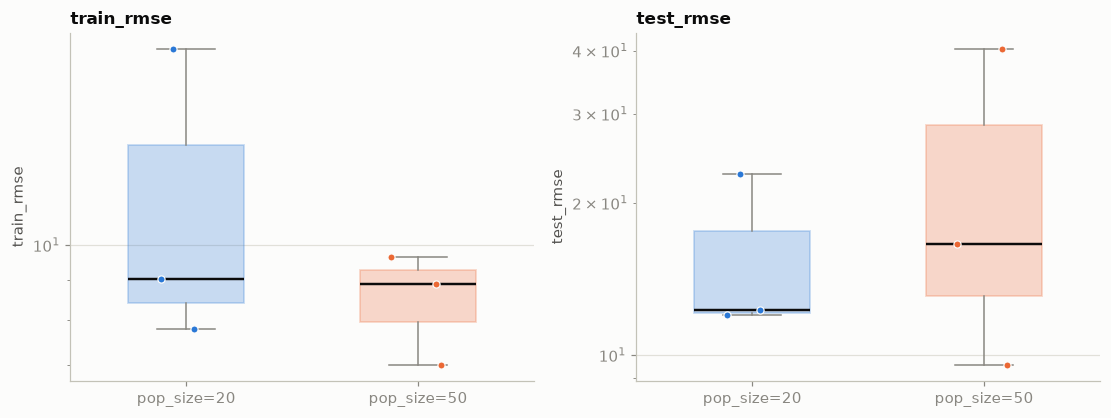

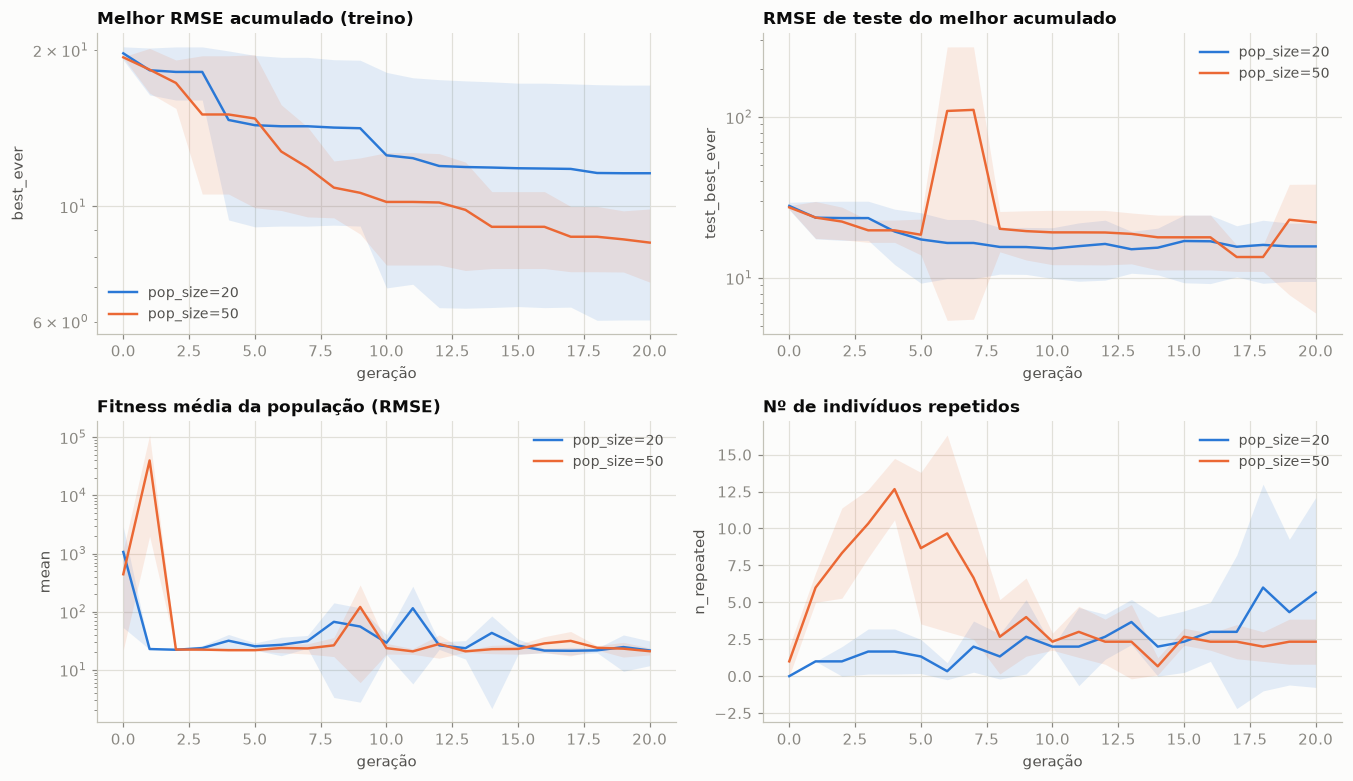


================  concrete  ================
RMSE de treino do melhor acumulado (média ± desvio) em gerações selecionadas:


,g=10,g=20
pop_size=20,22.64 ± 4.9,16.63 ± 0.12
pop_size=50,20.49 ± 2.8,15.93 ± 0.86


RMSE de teste do melhor acumulado:


,g=10,g=20
pop_size=20,22.13 ± 4.9,16.11 ± 0.21
pop_size=50,20.39 ± 2.6,15.54 ± 0.65


#### concrete — tamanho da população

,train_mean,train_std,train_median,test_mean,test_std,test_median,gap_mean,best_size,best_depth,time_s,n_runs
pop_size=20,16.6341,0.1160,16.6030,16.1102,0.2094,16.0156,-0.5239,33.0,6.6667,0.0383,3.0
pop_size=50,15.9330,0.8632,16.3204,15.5444,0.6494,15.7848,-0.3886,24.0,7.0000,0.0733,3.0


Kruskal-Wallis (train_rmse): p = 0.04953


,a,b,mediana_a,mediana_b,p,p_holm,signif_5%
0,pop_size=20,pop_size=50,16.603,16.3204,0.1,0.1,False


Kruskal-Wallis (test_rmse): p = 0.2752


,a,b,mediana_a,mediana_b,p,p_holm,signif_5%
0,pop_size=20,pop_size=50,16.0156,15.7848,0.4,0.4,False


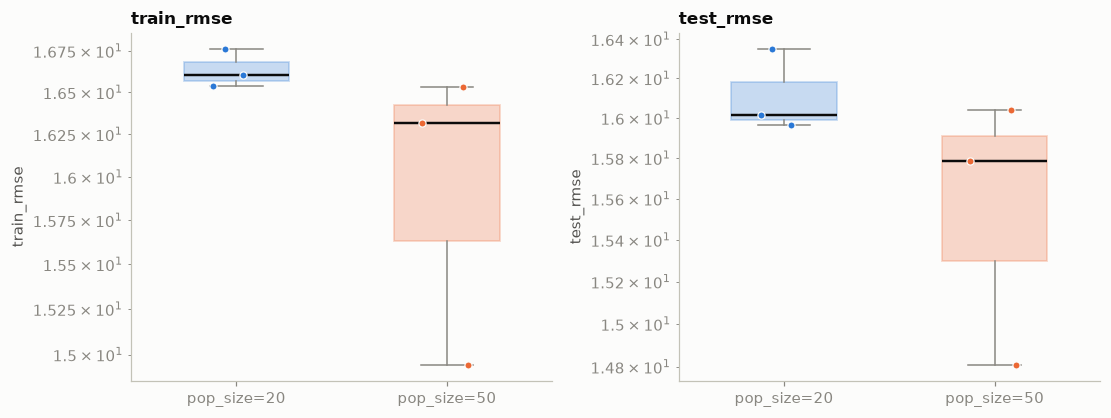

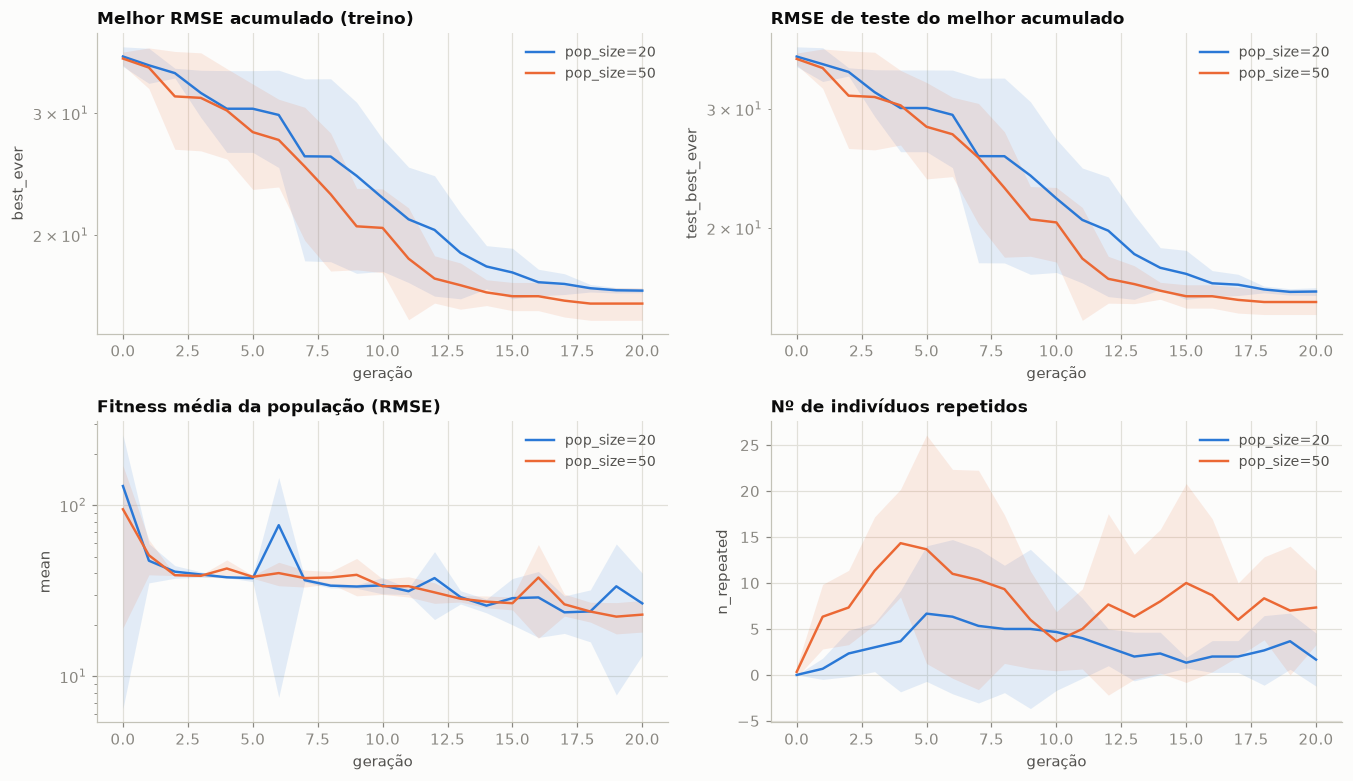

In [9]:
CHECKPOINTS = sorted({g for g in (10, 25, 50, 100, 200, 500) if g <= G_MAX} | {G_MAX})

for n in STUDY:
    print(f"\n================  {n}  ================")
    print("RMSE de treino do melhor acumulado (média ± desvio) em gerações selecionadas:")
    display(checkpoint_table(pop_res[n], CHECKPOINTS, "best_ever"))
    print("RMSE de teste do melhor acumulado:")
    display(checkpoint_table(pop_res[n], CHECKPOINTS, "test_best_ever"))
    report(pop_res[n], title=f"{n} — tamanho da população")

## Análise (1)

> **Resultado:** na `synth1`, aumentar a população de 20 para 50 reduziu o RMSE de treino em 20 gerações (11,59 para 8,52), mas elevou o RMSE de teste (15,71 para 22,16) e o tempo médio (0,034 s para 0,062 s). Na `concrete`, a população 50 foi melhor em treino (15,93 contra 16,63) e teste (15,54 contra 16,11), com aproximadamente o dobro do tempo. Com apenas três repetições, nenhum contraste passou pela correção de Holm (p ajustado ≥ 0,10).
>
> As curvas da `concrete` ainda melhoram entre as gerações 10 e 20; na `synth1`, a população 50 também melhora no treino, mas o teste piora, sinalizando sobreajuste. A população 50 foi escolhida por ser a melhor configuração média e por oferecer ganho claro na `concrete`; o número de gerações foi mantido em 20, pois é o horizonte executado nesta versão. A diversidade cai parcialmente: os indivíduos finais ficam maiores e mais profundos, sobretudo com população 50, o que também sugere bloat.

In [10]:
# ✍️ Decisão (por padrão: menor RMSE médio de treino entre os tamanhos testados). Sobrescreva se quiser.
POP_OVERRIDE = {}      # ex.: {"synth1": 100, "concrete": 500}
GEN_OVERRIDE = {}      # ex.: {"synth1": 50}

CHOSEN = {}
for n in STUDY:
    pop = POP_OVERRIDE.get(n) or int(best_config(pop_res[n]).split("=")[1])
    CHOSEN[n] = BASE[n].replace(pop_size=pop, generations=GEN_OVERRIDE.get(n, G_MAX))
    print(f"{n}: pop_size={CHOSEN[n].pop_size}, generations={CHOSEN[n].generations}")

synth1: pop_size=50, generations=20
concrete: pop_size=50, generations=20


## 3.2 Passo 2 — Método de seleção

Com população e gerações fixas, trocamos apenas o **método de seleção**: roleta, torneio ($k=2$) e
$\epsilon$-lexicase (MAD dinâmico, como no enunciado). A flag `EXTRA_SELECTION` inclui variantes
opcionais (torneio $k=5$, lexicase clássico e $\epsilon$ estático). Além de erro de treino e de teste,
observamos o **tempo de execução** (o lexicase é mais caro por avaliar casos sequencialmente) e a
**diversidade** (indivíduos repetidos).

synth1: 3 config × 3 runs:   0%|          | 0/9 [00:00<?, ?it/s]

[synth1] 9 execuções em 0.4s


#### synth1 — método de seleção

,train_mean,train_std,train_median,test_mean,test_std,test_median,gap_mean,best_size,best_depth,time_s,n_runs
roulette,7.1784,4.3368,9.0279,10.6683,6.7623,12.0020,3.4899,9.3333,4.3333,0.0525,3.0
tournament k=2,8.5159,1.3695,8.9032,22.1614,16.1120,16.6078,13.6455,19.6667,6.0000,0.0636,3.0
lexicase (ε-MAD),2.7660,0.5755,2.9513,4.7430,1.8713,5.2738,1.9770,17.6667,6.3333,0.2680,3.0


Kruskal-Wallis (train_rmse): p = 0.1931


,a,b,mediana_a,mediana_b,p,p_holm,signif_5%
0,roulette,tournament k=2,9.0279,8.9032,1.0,1.0,False
1,roulette,lexicase (ε-MAD),9.0279,2.9513,0.4,0.8,False
2,tournament k=2,lexicase (ε-MAD),8.9032,2.9513,0.1,0.3,False


Kruskal-Wallis (test_rmse): p = 0.1479


,a,b,mediana_a,mediana_b,p,p_holm,signif_5%
0,roulette,tournament k=2,12.0020,16.6078,0.7,0.8,False
1,roulette,lexicase (ε-MAD),12.0020,5.2738,0.4,0.8,False
2,tournament k=2,lexicase (ε-MAD),16.6078,5.2738,0.1,0.3,False


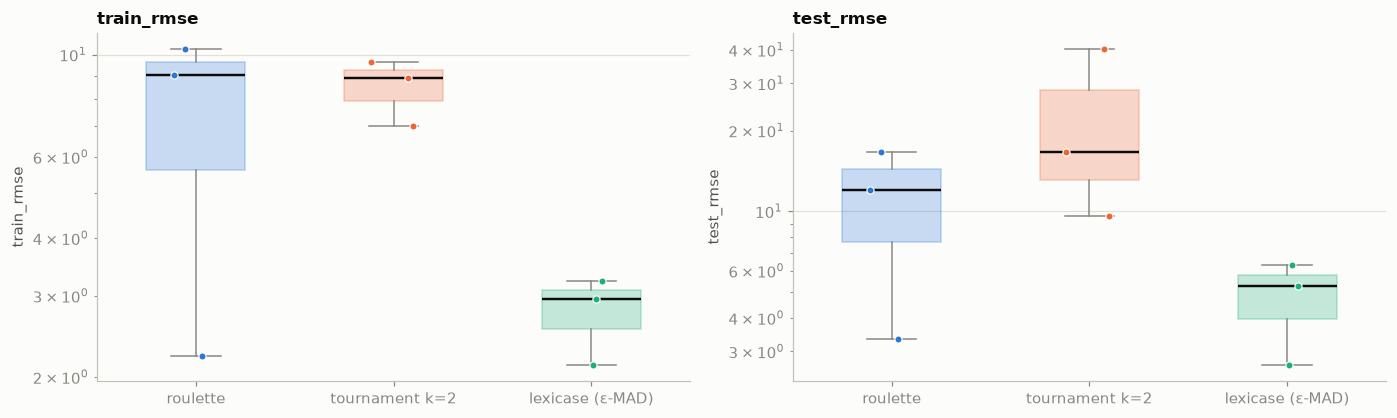

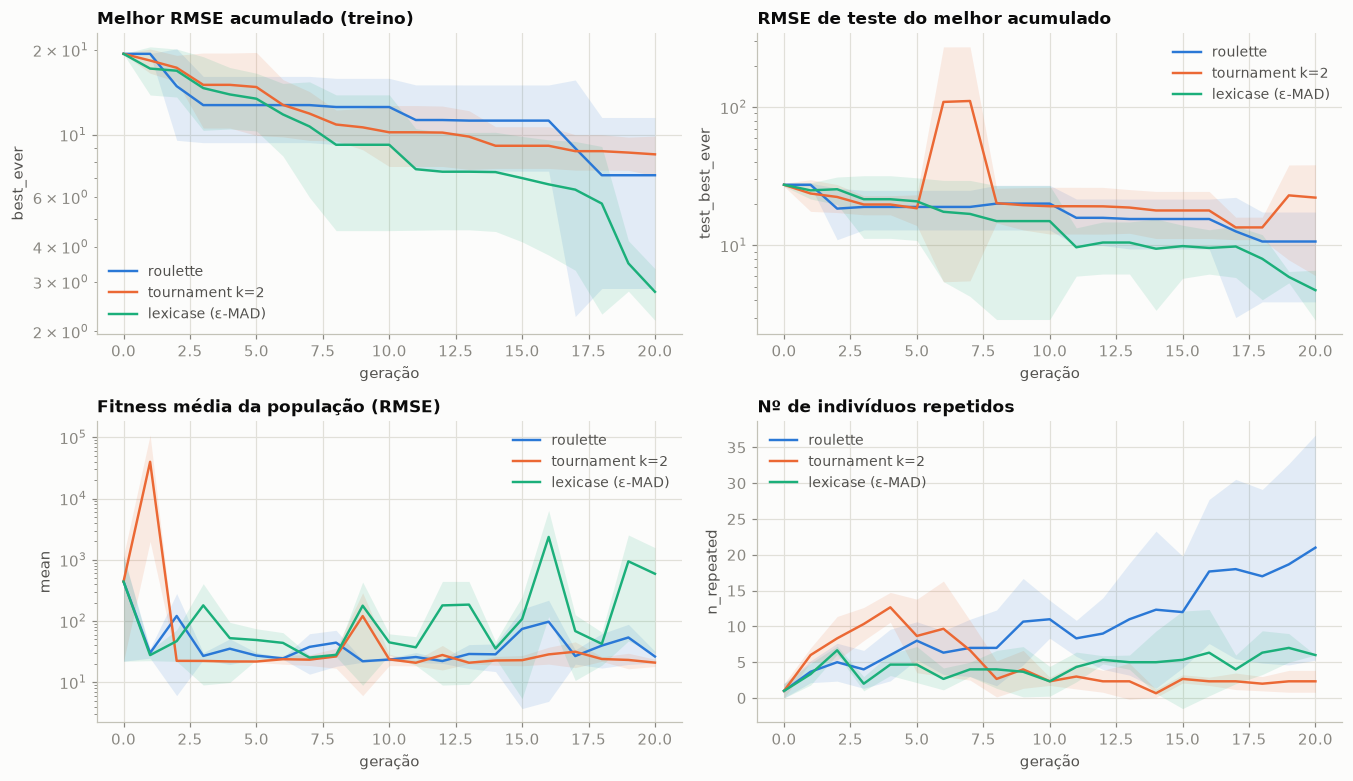

concrete: 3 config × 3 runs:   0%|          | 0/9 [00:00<?, ?it/s]

[concrete] 9 execuções em 1.2s


#### concrete — método de seleção

,train_mean,train_std,train_median,test_mean,test_std,test_median,gap_mean,best_size,best_depth,time_s,n_runs
roulette,17.4303,1.9933,17.4790,16.9600,1.9500,16.9728,-0.4703,12.6667,5.6667,0.0639,3.0
tournament k=2,15.9330,0.8632,16.3204,15.5444,0.6494,15.7848,-0.3886,24.0000,7.0000,0.0710,3.0
lexicase (ε-MAD),14.7308,1.1272,14.1464,14.1168,1.0897,13.5283,-0.6141,35.0000,7.0000,1.0281,3.0


Kruskal-Wallis (train_rmse): p = 0.1479


,a,b,mediana_a,mediana_b,p,p_holm,signif_5%
0,roulette,tournament k=2,17.4790,16.3204,0.4,0.6,False
1,roulette,lexicase (ε-MAD),17.4790,14.1464,0.2,0.6,False
2,tournament k=2,lexicase (ε-MAD),16.3204,14.1464,0.2,0.6,False


Kruskal-Wallis (test_rmse): p = 0.1479


,a,b,mediana_a,mediana_b,p,p_holm,signif_5%
0,roulette,tournament k=2,16.9728,15.7848,0.4,0.6,False
1,roulette,lexicase (ε-MAD),16.9728,13.5283,0.2,0.6,False
2,tournament k=2,lexicase (ε-MAD),15.7848,13.5283,0.2,0.6,False


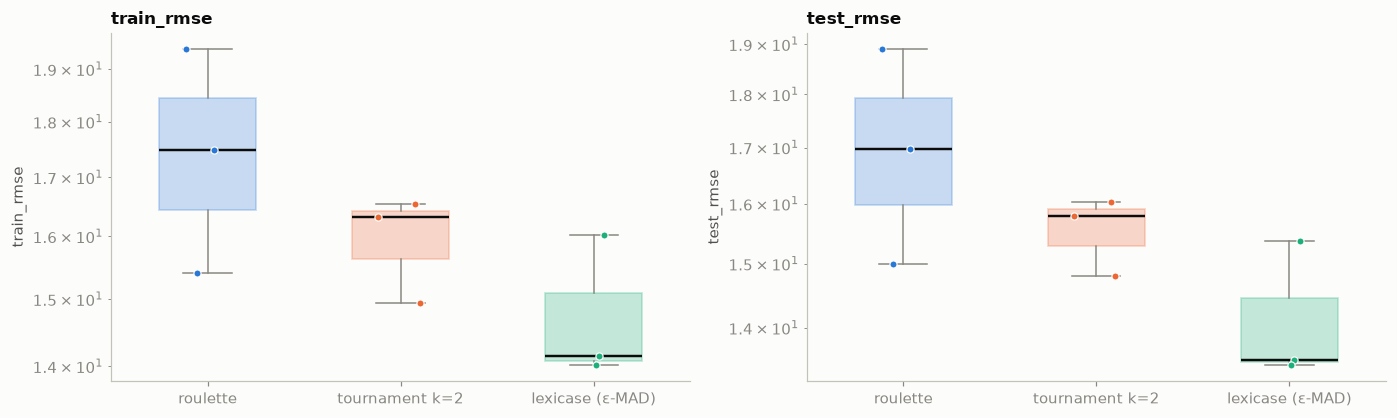

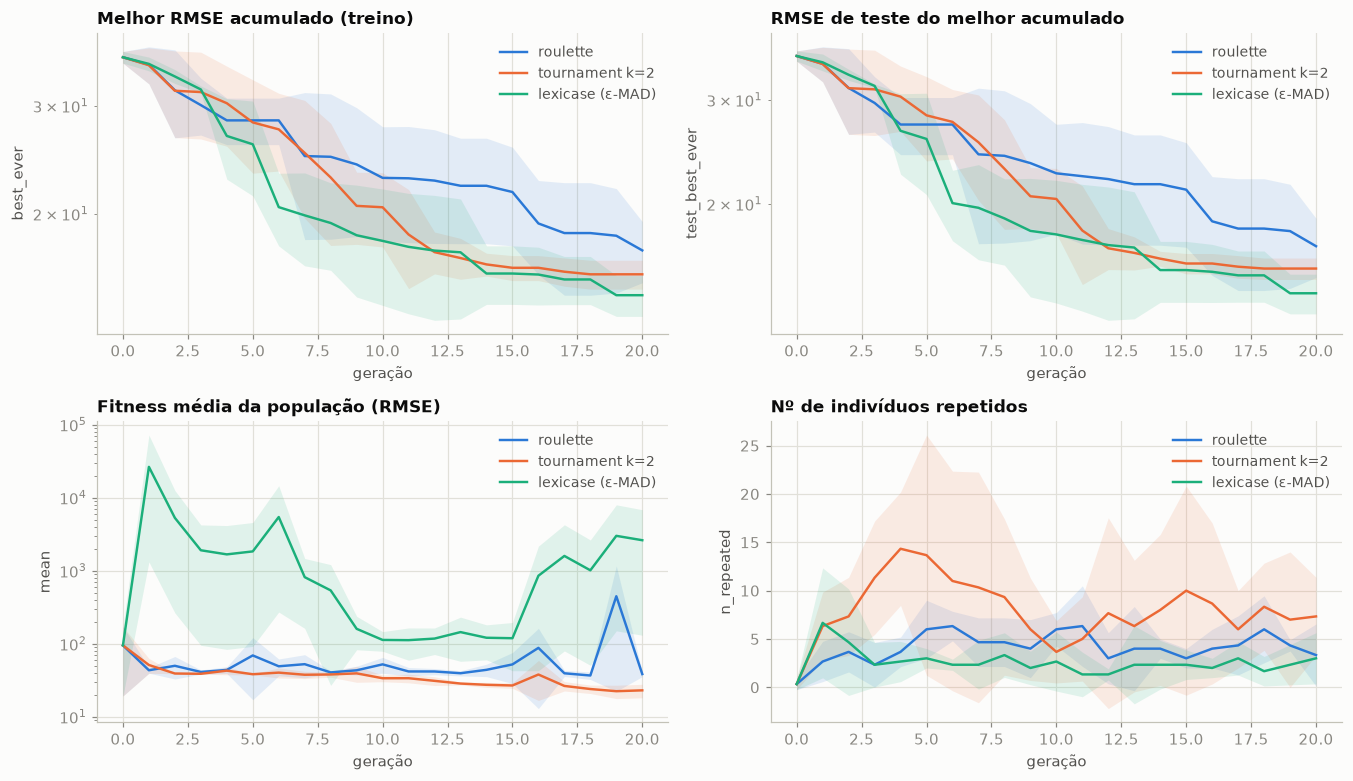

In [11]:
EXTRA_SELECTION = False

def selection_configs(cfg, extra=EXTRA_SELECTION):
    out = {
        "roulette":        cfg.replace(selection="roulette"),
        "tournament k=2":  cfg.replace(selection="tournament", tournament_size=2),
        "lexicase (ε-MAD)": cfg.replace(selection="lexicase", lexicase_epsilon="dynamic"),
    }
    if extra:
        out["tournament k=5"] = cfg.replace(selection="tournament", tournament_size=5)
        out["lexicase clássico (ε=0)"] = cfg.replace(selection="lexicase", lexicase_epsilon="none")
        out["lexicase ε estático"] = cfg.replace(selection="lexicase", lexicase_epsilon="static")
    return out

sel_res = {}
for n in STUDY:
    sel_res[n] = compare_configs(selection_configs(CHOSEN[n]), DATA[n], n_runs=N_RUNS,
                                 base_seed=BASE_SEED, n_jobs=N_JOBS)
    report(sel_res[n], title=f"{n} — método de seleção")

## Análise (2)
>
> **Resultado:** a seleção por ε-lexicase teve os menores erros médios nas duas bases: treino/teste de 2,77/4,74 na `synth1` e 14,73/14,12 na `concrete`; roleta ficou em 7,18/10,67 e 17,43/16,96, respectivamente. O torneio foi intermediário na `concrete`, mas pior na `synth1`. Nenhum resultado foi estatisticamente significativo após Holm (p ajustado mínimo de 0,30 na `synth1` e 0,60 na `concrete`), portanto a escolha é uma evidência empírica, não uma confirmação inferencial.
>
> O lexicase custa mais: cerca de 0,268 s contra 0,053–0,064 s na `synth1` e 1,03 s contra 0,064–0,071 s na `concrete`. Ainda assim, a redução do gap treino-teste e do erro justifica adotá-lo. A maior pressão seletiva melhora o desempenho, mas a análise de diversidade deve ser acompanhada porque os indivíduos finais são maiores.

In [12]:
# ✍️ Decisão (por padrão: menor RMSE médio de treino). Para forçar um método, defina SEL_OVERRIDE = {"synth1": "roulette"}
SEL_OVERRIDE = {}
for n in STUDY:
    chosen_name = SEL_OVERRIDE.get(n) or best_config(sel_res[n])
    CHOSEN[n] = sel_res[n][chosen_name].config
    print(f"{n}: seleção escolhida = {chosen_name}")

synth1: seleção escolhida = lexicase (ε-MAD)
concrete: seleção escolhida = lexicase (ε-MAD)


## 3.3 Passo 3 — Probabilidades de cruzamento ($p_c$) e de mutação ($p_m$)

### 3.3.1 Duas configurações e a contribuição dos operadores

Comparamos duas configurações: **A** ($p_c=0.9$, $p_m=0.05$) e **B** ($p_c=0.6$, $p_m=0.3$). Para
ambas, medimos o **efeito dos operadores** ao longo de toda a evolução: em quantos casos os filhos de
cruzamento são **melhores / piores que a fitness média dos pais** (e melhores que o melhor pai), e em
quantos casos a mutação **melhora / piora** o indivíduo mutado. Observação: quando o cruzamento não é
aplicado ($1-p_c$), os pais são clonados e, ainda assim, podem ser mutados.

synth1: 2 config × 3 runs:   0%|          | 0/6 [00:00<?, ?it/s]

[synth1] 6 execuções em 0.6s


#### synth1 — configurações A e B

,train_mean,train_std,train_median,test_mean,test_std,test_median,gap_mean,best_size,best_depth,time_s,n_runs
"A: pc=0.9, pm=0.05",2.7660,0.5755,2.9513,4.7430,1.8713,5.2738,1.9770,17.6667,6.3333,0.2982,3.0
"B: pc=0.6, pm=0.3",5.3548,3.2454,5.1548,9.6396,5.6338,11.8420,4.2848,21.3333,6.6667,0.3975,3.0


Kruskal-Wallis (train_rmse): p = 0.2752


,a,b,mediana_a,mediana_b,p,p_holm,signif_5%
0,"A: pc=0.9, pm=0.05","B: pc=0.6, pm=0.3",2.9513,5.1548,0.4,0.4,False


Kruskal-Wallis (test_rmse): p = 0.2752


,a,b,mediana_a,mediana_b,p,p_holm,signif_5%
0,"A: pc=0.9, pm=0.05","B: pc=0.6, pm=0.3",5.2738,11.842,0.4,0.4,False


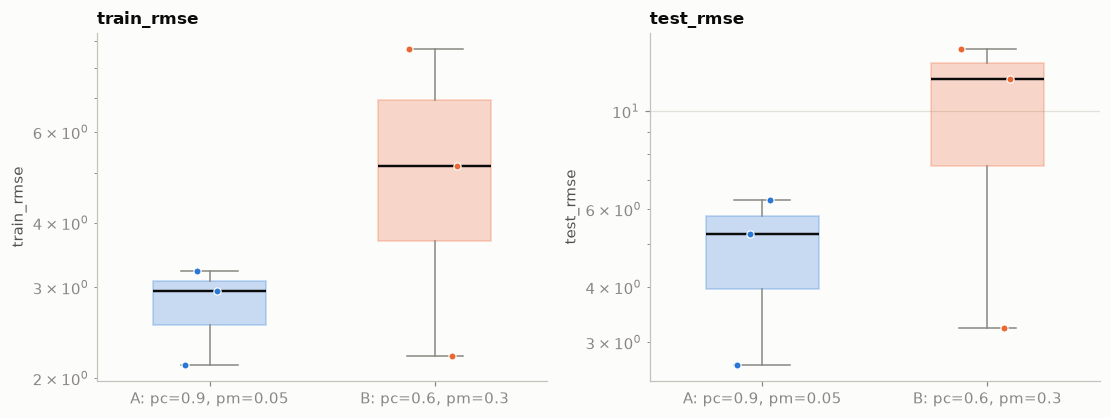

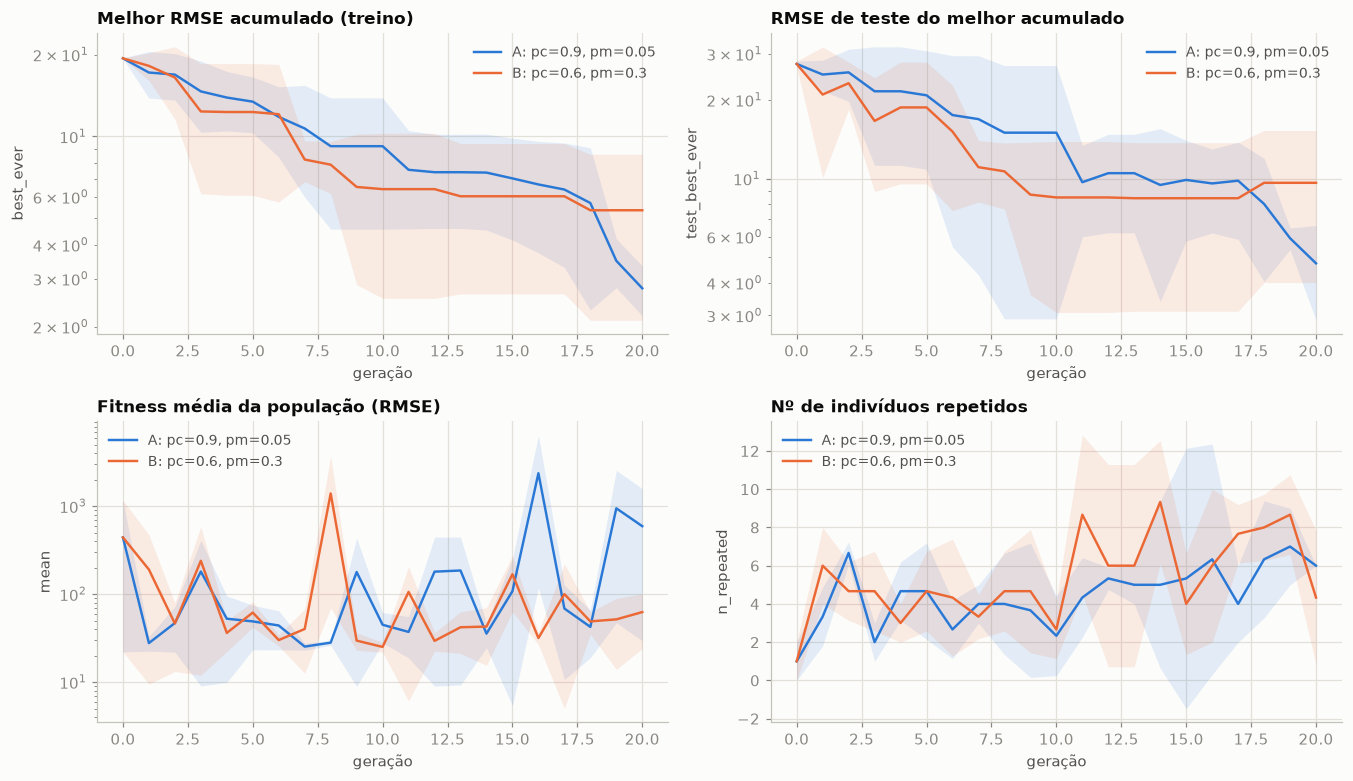

Efeito dos operadores (todas as gerações e execuções):


,"A: pc=0.9, pm=0.05","B: pc=0.6, pm=0.3"
xo_filhos,2640.00,1828.00
xo_melhor_que_media_pais_%,34.85,31.18
xo_igual_%,1.36,1.42
xo_pior_que_media_pais_%,63.79,67.40
xo_melhor_que_melhor_pai_%,12.42,12.47
xo_falhas_%,0.00,0.33
mut_indivs,162.00,946.00
mut_melhor_%,35.80,35.73
mut_igual_%,2.47,2.85
mut_pior_%,61.73,61.42


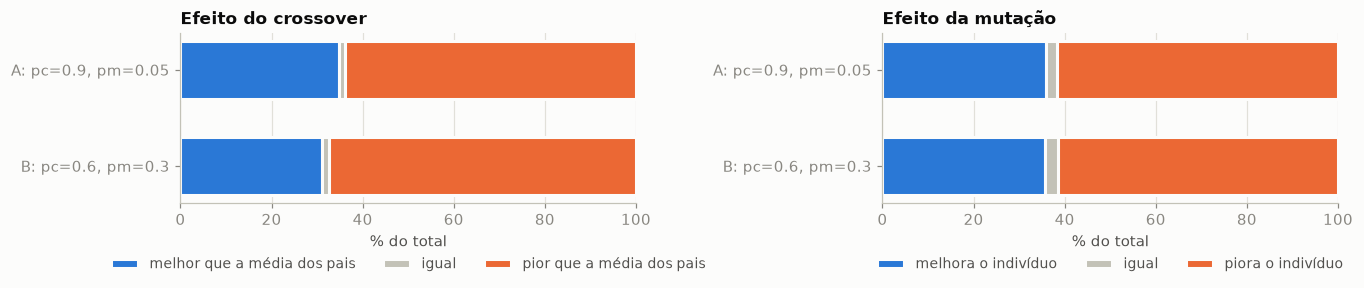

concrete: 2 config × 3 runs:   0%|          | 0/6 [00:00<?, ?it/s]

[concrete] 6 execuções em 3.1s


#### concrete — configurações A e B

,train_mean,train_std,train_median,test_mean,test_std,test_median,gap_mean,best_size,best_depth,time_s,n_runs
"A: pc=0.9, pm=0.05",14.7308,1.1272,14.1464,14.1168,1.0897,13.5283,-0.6141,35.0000,7.0,1.3429,3.0
"B: pc=0.6, pm=0.3",14.1803,1.0939,14.1404,13.8051,0.9201,13.5821,-0.3752,35.3333,7.0,2.2591,3.0


Kruskal-Wallis (train_rmse): p = 0.5127


,a,b,mediana_a,mediana_b,p,p_holm,signif_5%
0,"A: pc=0.9, pm=0.05","B: pc=0.6, pm=0.3",14.1464,14.1404,0.7,0.7,False


Kruskal-Wallis (test_rmse): p = 0.8273


,a,b,mediana_a,mediana_b,p,p_holm,signif_5%
0,"A: pc=0.9, pm=0.05","B: pc=0.6, pm=0.3",13.5283,13.5821,1.0,1.0,False


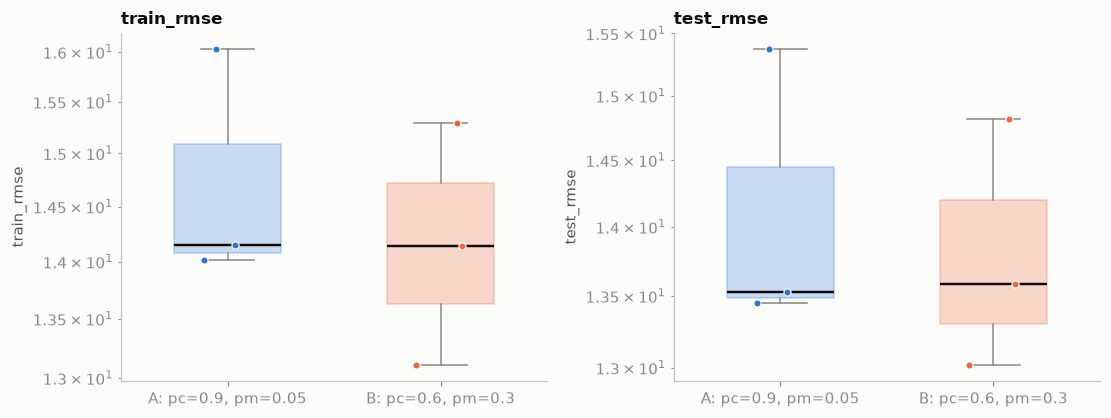

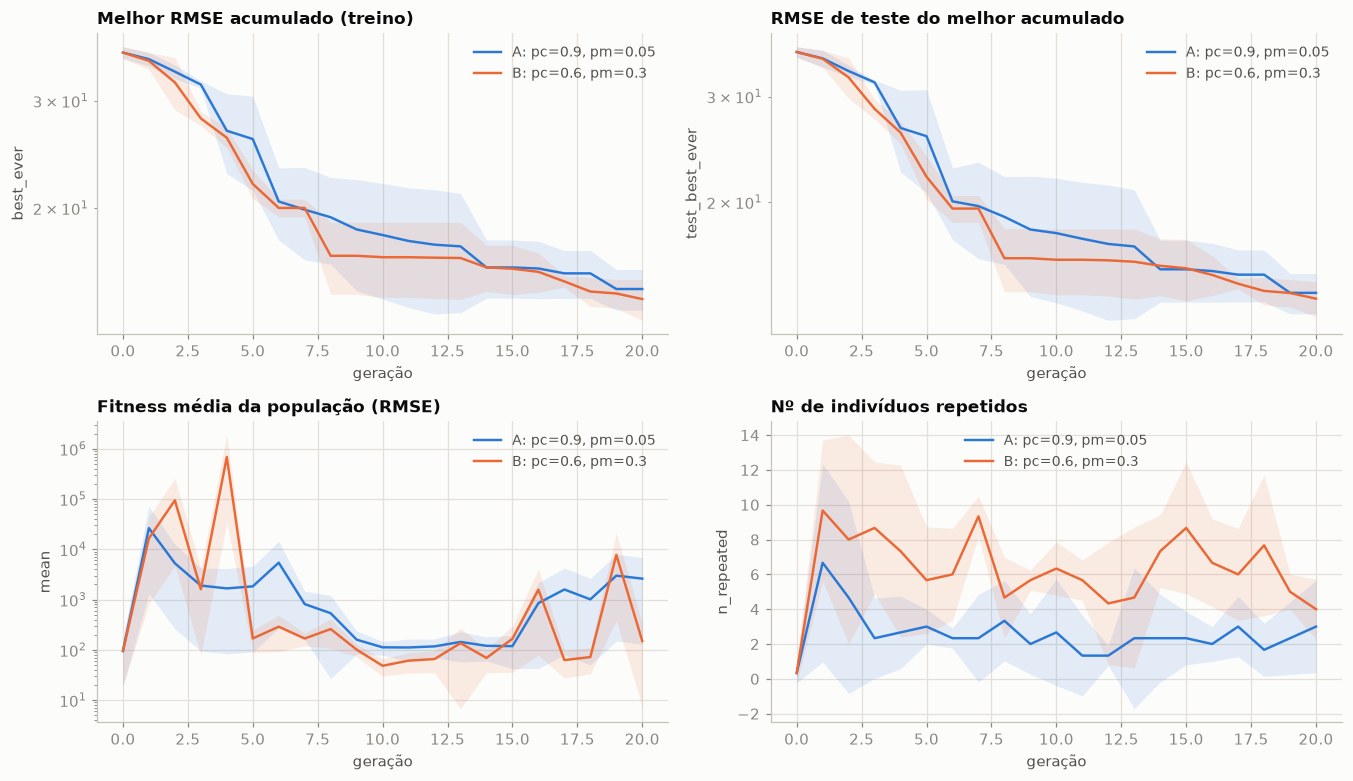

Efeito dos operadores (todas as gerações e execuções):


,"A: pc=0.9, pm=0.05","B: pc=0.6, pm=0.3"
xo_filhos,2688.00,1804.00
xo_melhor_que_media_pais_%,46.80,39.52
xo_igual_%,1.12,2.22
xo_pior_que_media_pais_%,52.08,58.26
xo_melhor_que_melhor_pai_%,20.80,13.64
xo_falhas_%,0.30,0.00
mut_indivs,160.00,911.00
mut_melhor_%,43.12,30.85
mut_igual_%,0.62,0.99
mut_pior_%,56.25,68.17


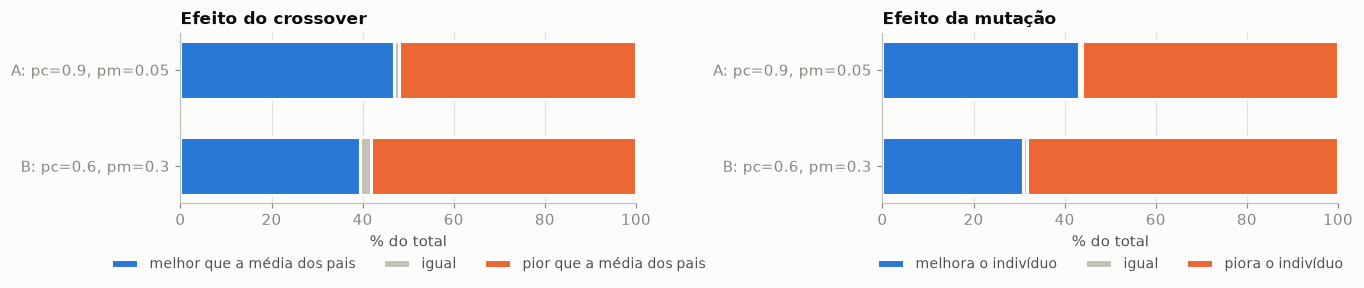

In [13]:
def pcpm_configs(cfg):
    return {"A: pc=0.9, pm=0.05": cfg.replace(pc=0.9, pm=0.05),
            "B: pc=0.6, pm=0.3":  cfg.replace(pc=0.6, pm=0.3)}

ab_res = {}
for n in STUDY:
    ab_res[n] = compare_configs(pcpm_configs(CHOSEN[n]), DATA[n], n_runs=N_RUNS,
                                base_seed=BASE_SEED, n_jobs=N_JOBS)
    report(ab_res[n], title=f"{n} — configurações A e B")
    print("Efeito dos operadores (todas as gerações e execuções):")
    display(operator_effects(ab_res[n]).T.round(2))
    fig, axes = plt.subplots(1, 2, figsize=(12.5, 2.9))
    P.plot_operator_effects(ab_res[n], "crossover", ax=axes[0])
    P.plot_operator_effects(ab_res[n], "mutation", ax=axes[1])
    fig.tight_layout(); plt.show()

## Análise (3.1)
>
> **Resultado:** na `synth1`, a configuração A (`p_c=0,9`, `p_m=0,05`) foi melhor que B no treino/teste (2,77/4,74 contra 5,35/9,64) e também mais rápida. Na `concrete`, B teve RMSE ligeiramente menor (14,18/13,81 contra 14,73/14,12), mas demorou mais e a diferença não foi significativa (Holm p=0,40 no treino e 1,00 no teste). Em A, o cruzamento foi melhor que a média dos pais em 34,85% dos filhos na `synth1` e 46,80% na `concrete`; a mutação melhorou 35,80% e 43,12% dos indivíduos, respectivamente. B aumentou mutações piores (61,42% e 68,17%).
>
> Assim, mantive A como ponto de partida: o ganho consistente na `synth1` e o menor custo compensam a pequena vantagem de B na `concrete`.

### 3.3.2 Variação de $p_c$ e depois de $p_m$

Seguindo o guia, varia-se primeiro $p_c$ (com $p_m$ fixo) e, depois de escolhido $p_c$, varia-se $p_m$.

synth1: 4 config × 3 runs:   0%|          | 0/12 [00:00<?, ?it/s]

[synth1] 12 execuções em 1.2s


#### synth1 — variação de pc (pm = 0.05)

,train_mean,train_std,train_median,test_mean,test_std,test_median,gap_mean,best_size,best_depth,time_s,n_runs
pc=0.5,4.9153,2.7013,6.4007,6.2335,3.8522,7.7709,1.3181,33.0000,6.3333,0.8311,3.0
pc=0.7,6.5200,6.5210,3.2214,6.4120,5.4731,3.8797,-0.1080,22.6667,5.6667,0.8548,3.0
pc=0.9,2.7660,0.5755,2.9513,4.7430,1.8713,5.2738,1.9770,17.6667,6.3333,0.4195,3.0
pc=1.0,6.6268,5.5208,5.9589,6.2541,4.1585,8.4046,-0.3727,24.6667,6.3333,0.1696,3.0


Kruskal-Wallis (train_rmse): p = 0.8629


,a,b,mediana_a,mediana_b,p,p_holm,signif_5%
0,pc=0.5,pc=0.7,6.4007,3.2214,1.0,1.0,False
1,pc=0.5,pc=0.9,6.4007,2.9513,0.7,1.0,False
2,pc=0.5,pc=1.0,6.4007,5.9589,1.0,1.0,False
3,pc=0.7,pc=0.9,3.2214,2.9513,0.7,1.0,False
4,pc=0.7,pc=1.0,3.2214,5.9589,1.0,1.0,False
5,pc=0.9,pc=1.0,2.9513,5.9589,0.7,1.0,False


Kruskal-Wallis (test_rmse): p = 0.9559


,a,b,mediana_a,mediana_b,p,p_holm,signif_5%
0,pc=0.5,pc=0.7,7.7709,3.8797,1.0,1.0,False
1,pc=0.5,pc=0.9,7.7709,5.2738,0.7,1.0,False
2,pc=0.5,pc=1.0,7.7709,8.4046,1.0,1.0,False
3,pc=0.7,pc=0.9,3.8797,5.2738,1.0,1.0,False
4,pc=0.7,pc=1.0,3.8797,8.4046,1.0,1.0,False
5,pc=0.9,pc=1.0,5.2738,8.4046,0.7,1.0,False


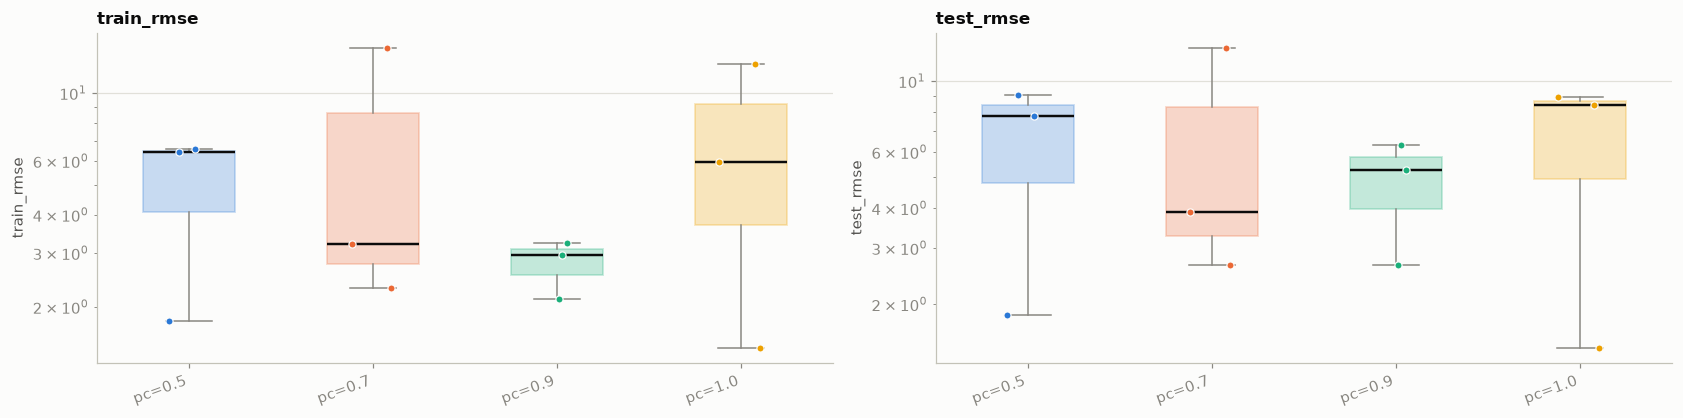

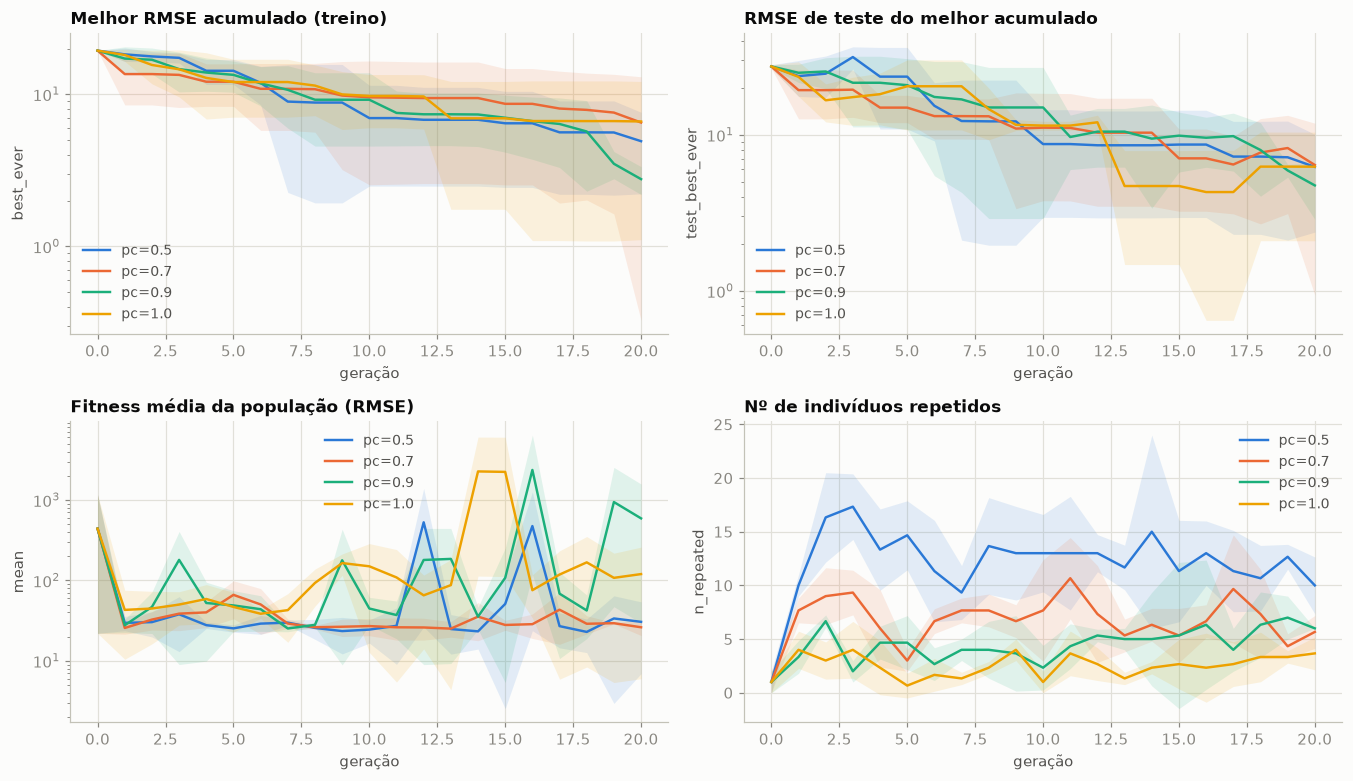

concrete: 4 config × 3 runs:   0%|          | 0/12 [00:00<?, ?it/s]

[concrete] 12 execuções em 5.2s


#### concrete — variação de pc (pm = 0.05)

,train_mean,train_std,train_median,test_mean,test_std,test_median,gap_mean,best_size,best_depth,time_s,n_runs
pc=0.5,15.5564,2.1401,14.8809,15.1975,2.2029,14.7209,-0.3589,31.0000,7.0,3.7185,3.0
pc=0.7,13.8677,1.8031,14.4085,13.6953,1.7201,14.6467,-0.1724,29.3333,7.0,2.6282,3.0
pc=0.9,14.7308,1.1272,14.1464,14.1168,1.0897,13.5283,-0.6141,35.0000,7.0,0.9170,3.0
pc=1.0,14.3166,2.2382,14.2761,13.7193,1.9200,13.4888,-0.5973,31.3333,7.0,0.8927,3.0


Kruskal-Wallis (train_rmse): p = 0.9217


,a,b,mediana_a,mediana_b,p,p_holm,signif_5%
0,pc=0.5,pc=0.7,14.8809,14.4085,0.7,1.0,False
1,pc=0.5,pc=0.9,14.8809,14.1464,1.0,1.0,False
2,pc=0.5,pc=1.0,14.8809,14.2761,0.7,1.0,False
3,pc=0.7,pc=0.9,14.4085,14.1464,1.0,1.0,False
4,pc=0.7,pc=1.0,14.4085,14.2761,1.0,1.0,False
5,pc=0.9,pc=1.0,14.1464,14.2761,1.0,1.0,False


Kruskal-Wallis (test_rmse): p = 0.9104


,a,b,mediana_a,mediana_b,p,p_holm,signif_5%
0,pc=0.5,pc=0.7,14.7209,14.6467,0.7,1.0,False
1,pc=0.5,pc=0.9,14.7209,13.5283,1.0,1.0,False
2,pc=0.5,pc=1.0,14.7209,13.4888,0.7,1.0,False
3,pc=0.7,pc=0.9,14.6467,13.5283,1.0,1.0,False
4,pc=0.7,pc=1.0,14.6467,13.4888,1.0,1.0,False
5,pc=0.9,pc=1.0,13.5283,13.4888,1.0,1.0,False


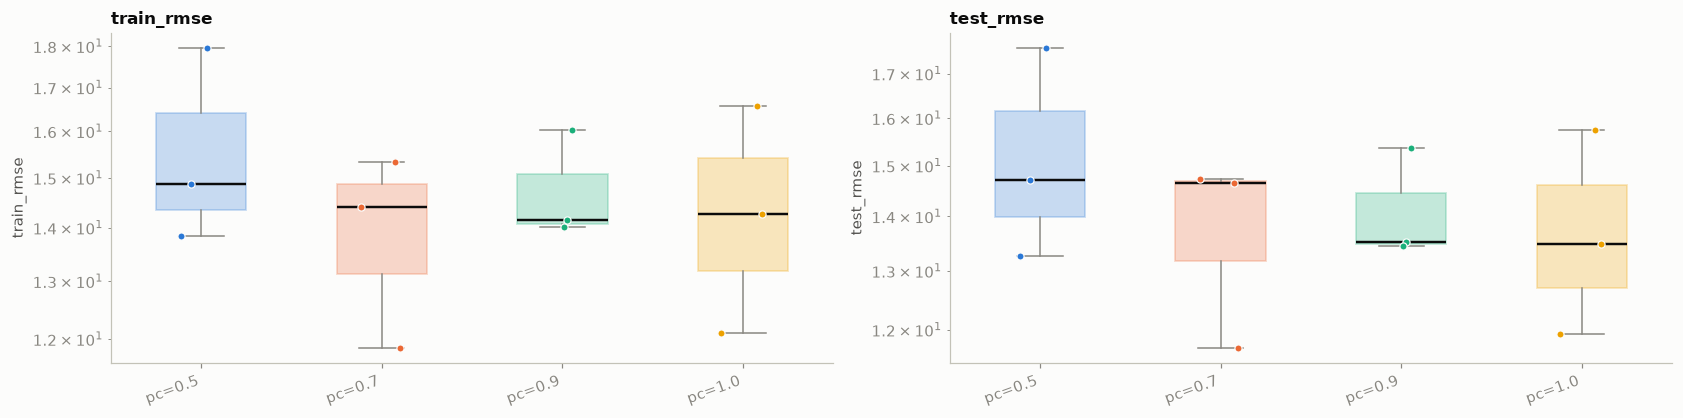

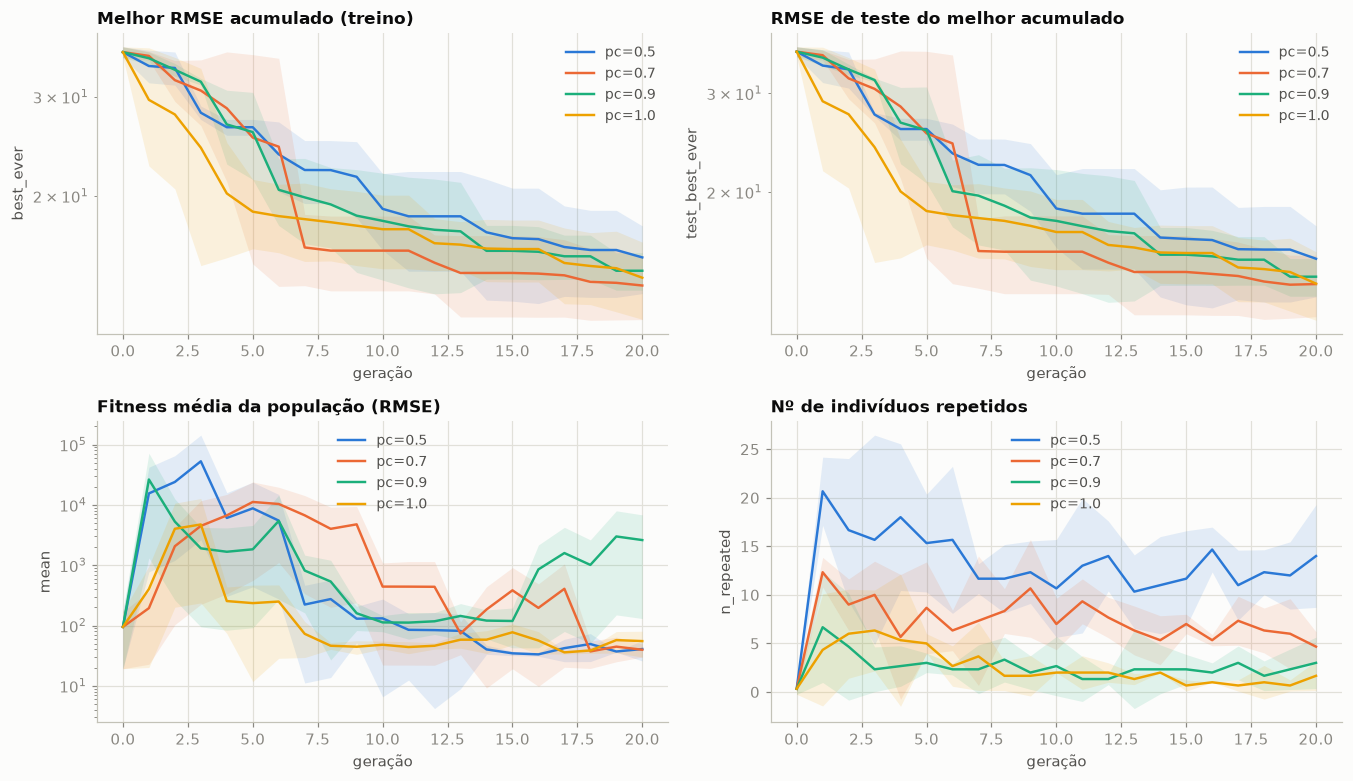

In [14]:
PC_VALUES = [0.5, 0.7, 0.9, 1.0]
PM_VALUES = [0.0, 0.05, 0.1, 0.2, 0.3]

pc_res, pm_res = {}, {}
for n in STUDY:
    pc_res[n] = sweep(CHOSEN[n], "pc", PC_VALUES, DATA[n], n_runs=N_RUNS, base_seed=BASE_SEED, n_jobs=N_JOBS)
    report(pc_res[n], title=f"{n} — variação de pc (pm = {CHOSEN[n].pm})")

## Análise (3.2)
>
> **Resultado:** não houve efeito monotônico de `p_c`. Na `synth1`, `p_c=0,9` obteve o menor treino (2,77) e teste (4,74); na `concrete`, `p_c=0,7` obteve 13,87/13,70. Os testes de Kruskal-Wallis não detectaram diferenças (p=0,863 e 0,922 no treino). Escolhi `p_c=0,9` para a `synth1` e `p_c=0,7` para a `concrete`, respeitando o melhor RMSE médio observado; a decisão deve ser tratada como preliminar devido às três repetições.

synth1: pc = 0.9
concrete: pc = 0.7


synth1: 5 config × 3 runs:   0%|          | 0/15 [00:00<?, ?it/s]

[synth1] 15 execuções em 0.5s


#### synth1 — variação de pm (pc = 0.9)

,train_mean,train_std,train_median,test_mean,test_std,test_median,gap_mean,best_size,best_depth,time_s,n_runs
pm=0.0,5.7193,3.5955,6.6019,8.1071,6.4537,7.4405,2.3877,20.3333,6.0000,0.2053,3.0
pm=0.05,2.7660,0.5755,2.9513,4.7430,1.8713,5.2738,1.9770,17.6667,6.3333,0.3466,3.0
pm=0.1,4.6324,4.7983,1.9946,8.7963,12.3829,2.3327,4.1639,21.3333,6.0000,0.2032,3.0
pm=0.2,6.2037,3.2141,7.9956,9.5374,5.7235,11.9252,3.3337,24.3333,7.0000,0.1408,3.0
pm=0.3,5.6780,3.6645,5.4823,10.8855,9.9660,9.0365,5.2075,20.6667,7.0000,0.1199,3.0


Kruskal-Wallis (train_rmse): p = 0.867


,a,b,mediana_a,mediana_b,p,p_holm,signif_5%
0,pm=0.0,pm=0.05,6.6019,2.9513,0.7,1.0,False
1,pm=0.0,pm=0.1,6.6019,1.9946,1.0,1.0,False
2,pm=0.0,pm=0.2,6.6019,7.9956,1.0,1.0,False
3,pm=0.0,pm=0.3,6.6019,5.4823,1.0,1.0,False
4,pm=0.05,pm=0.1,2.9513,1.9946,0.7,1.0,False
5,pm=0.05,pm=0.2,2.9513,7.9956,0.4,1.0,False
6,pm=0.05,pm=0.3,2.9513,5.4823,0.7,1.0,False
7,pm=0.1,pm=0.2,1.9946,7.9956,0.7,1.0,False
8,pm=0.1,pm=0.3,1.9946,5.4823,0.7,1.0,False
9,pm=0.2,pm=0.3,7.9956,5.4823,1.0,1.0,False


Kruskal-Wallis (test_rmse): p = 0.9047


,a,b,mediana_a,mediana_b,p,p_holm,signif_5%
0,pm=0.0,pm=0.05,7.4405,5.2738,0.7,1.0,False
1,pm=0.0,pm=0.1,7.4405,2.3327,1.0,1.0,False
2,pm=0.0,pm=0.2,7.4405,11.9252,1.0,1.0,False
3,pm=0.0,pm=0.3,7.4405,9.0365,1.0,1.0,False
4,pm=0.05,pm=0.1,5.2738,2.3327,0.7,1.0,False
5,pm=0.05,pm=0.2,5.2738,11.9252,0.4,1.0,False
6,pm=0.05,pm=0.3,5.2738,9.0365,0.7,1.0,False
7,pm=0.1,pm=0.2,2.3327,11.9252,0.7,1.0,False
8,pm=0.1,pm=0.3,2.3327,9.0365,1.0,1.0,False
9,pm=0.2,pm=0.3,11.9252,9.0365,1.0,1.0,False


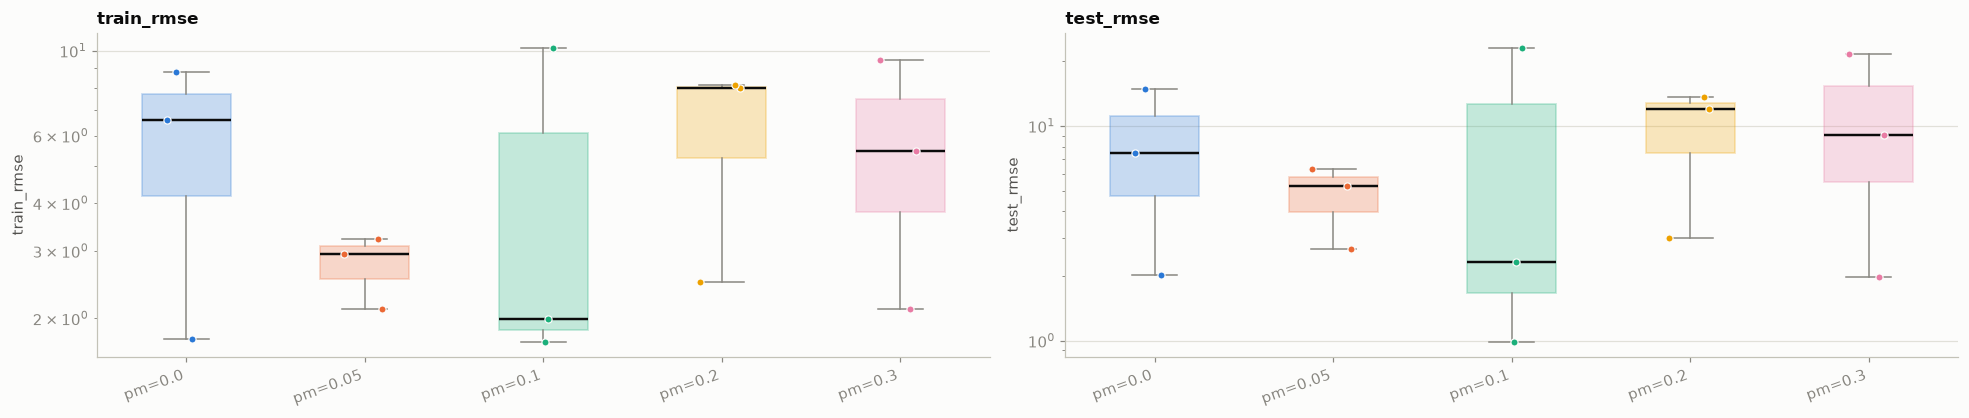

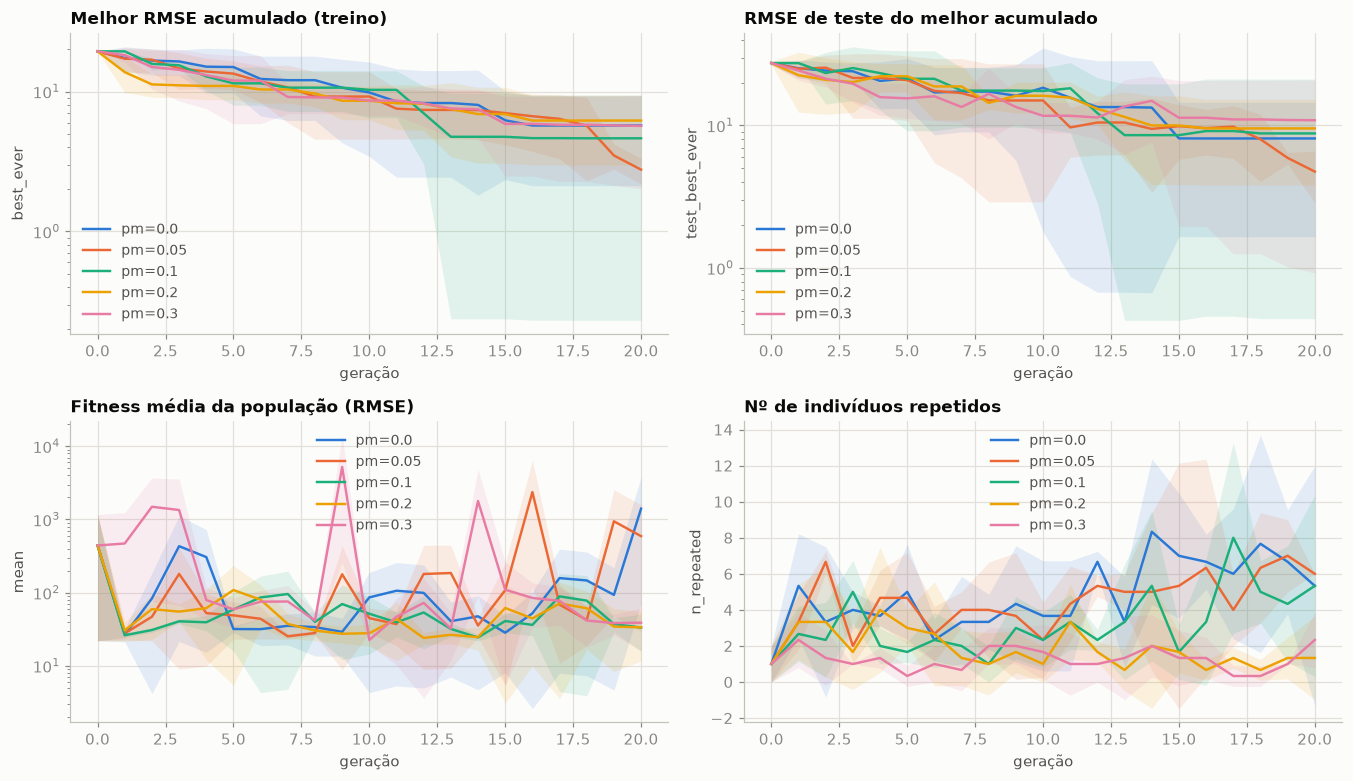

Efeito da mutação:


,mut_indivs,mut_melhor_%,mut_igual_%,mut_pior_%
pm=0.0,0.0,NaN,NaN,NaN
pm=0.05,162.0,35.80,2.47,61.73
pm=0.1,312.0,38.14,1.92,59.94
pm=0.2,595.0,36.97,3.53,59.50
pm=0.3,893.0,36.84,2.69,60.47


concrete: 5 config × 3 runs:   0%|          | 0/15 [00:00<?, ?it/s]

[concrete] 15 execuções em 5.2s


#### concrete — variação de pm (pc = 0.7)

,train_mean,train_std,train_median,test_mean,test_std,test_median,gap_mean,best_size,best_depth,time_s,n_runs
pm=0.0,15.0674,2.8918,16.6640,14.6927,2.6213,16.1331,-0.3747,24.0000,7.0,2.2806,3.0
pm=0.05,13.8677,1.8031,14.4085,13.6953,1.7201,14.6467,-0.1724,29.3333,7.0,2.0458,3.0
pm=0.1,16.1255,3.7210,14.6116,15.2048,3.2858,13.4362,-0.9207,32.3333,7.0,1.7289,3.0
pm=0.2,15.6373,1.1050,15.8420,15.5975,1.0159,15.3356,-0.0398,32.6667,7.0,1.4342,3.0
pm=0.3,14.4561,2.1305,13.9059,13.8848,2.2590,13.5895,-0.5712,23.6667,7.0,1.6481,3.0


Kruskal-Wallis (train_rmse): p = 0.8207


,a,b,mediana_a,mediana_b,p,p_holm,signif_5%
0,pm=0.0,pm=0.05,16.6640,14.4085,0.7,1.0,False
1,pm=0.0,pm=0.1,16.6640,14.6116,1.0,1.0,False
2,pm=0.0,pm=0.2,16.6640,15.8420,0.7,1.0,False
3,pm=0.0,pm=0.3,16.6640,13.9059,1.0,1.0,False
4,pm=0.05,pm=0.1,14.4085,14.6116,0.7,1.0,False
5,pm=0.05,pm=0.2,14.4085,15.8420,0.2,1.0,False
6,pm=0.05,pm=0.3,14.4085,13.9059,1.0,1.0,False
7,pm=0.1,pm=0.2,14.6116,15.8420,1.0,1.0,False
8,pm=0.1,pm=0.3,14.6116,13.9059,0.7,1.0,False
9,pm=0.2,pm=0.3,15.8420,13.9059,0.7,1.0,False


Kruskal-Wallis (test_rmse): p = 0.6747


,a,b,mediana_a,mediana_b,p,p_holm,signif_5%
0,pm=0.0,pm=0.05,16.1331,14.6467,0.7,1.0,False
1,pm=0.0,pm=0.1,16.1331,13.4362,1.0,1.0,False
2,pm=0.0,pm=0.2,16.1331,15.3356,1.0,1.0,False
3,pm=0.0,pm=0.3,16.1331,13.5895,1.0,1.0,False
4,pm=0.05,pm=0.1,14.6467,13.4362,1.0,1.0,False
5,pm=0.05,pm=0.2,14.6467,15.3356,0.1,1.0,False
6,pm=0.05,pm=0.3,14.6467,13.5895,1.0,1.0,False
7,pm=0.1,pm=0.2,13.4362,15.3356,0.7,1.0,False
8,pm=0.1,pm=0.3,13.4362,13.5895,1.0,1.0,False
9,pm=0.2,pm=0.3,15.3356,13.5895,0.4,1.0,False


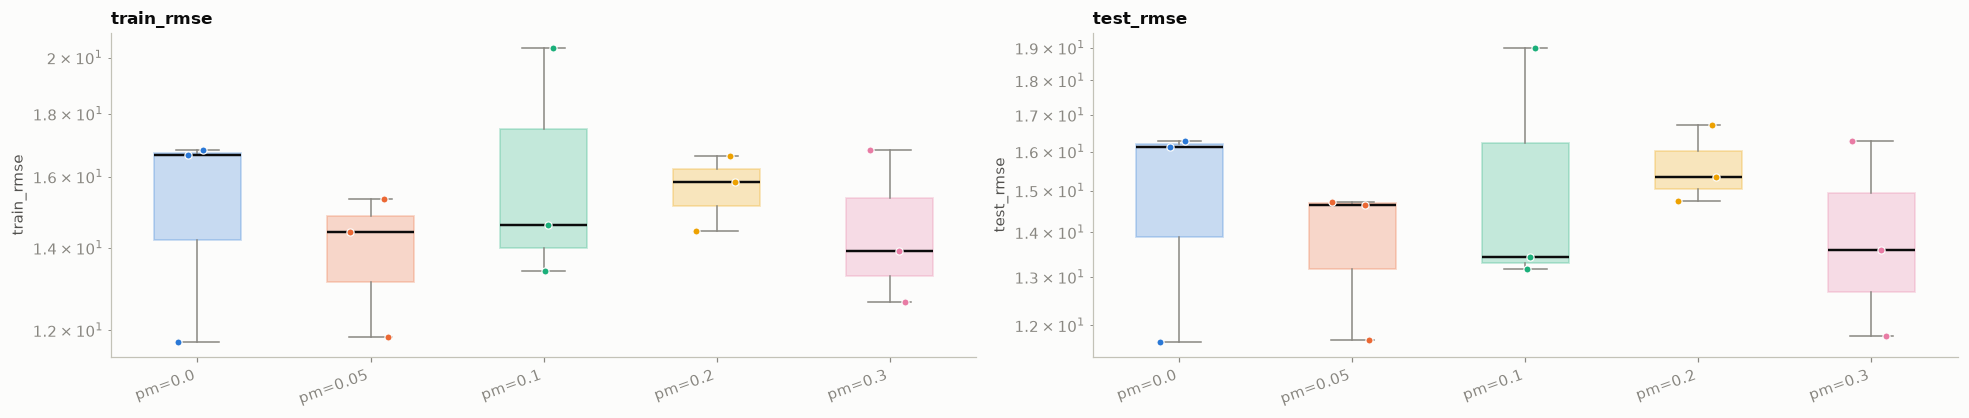

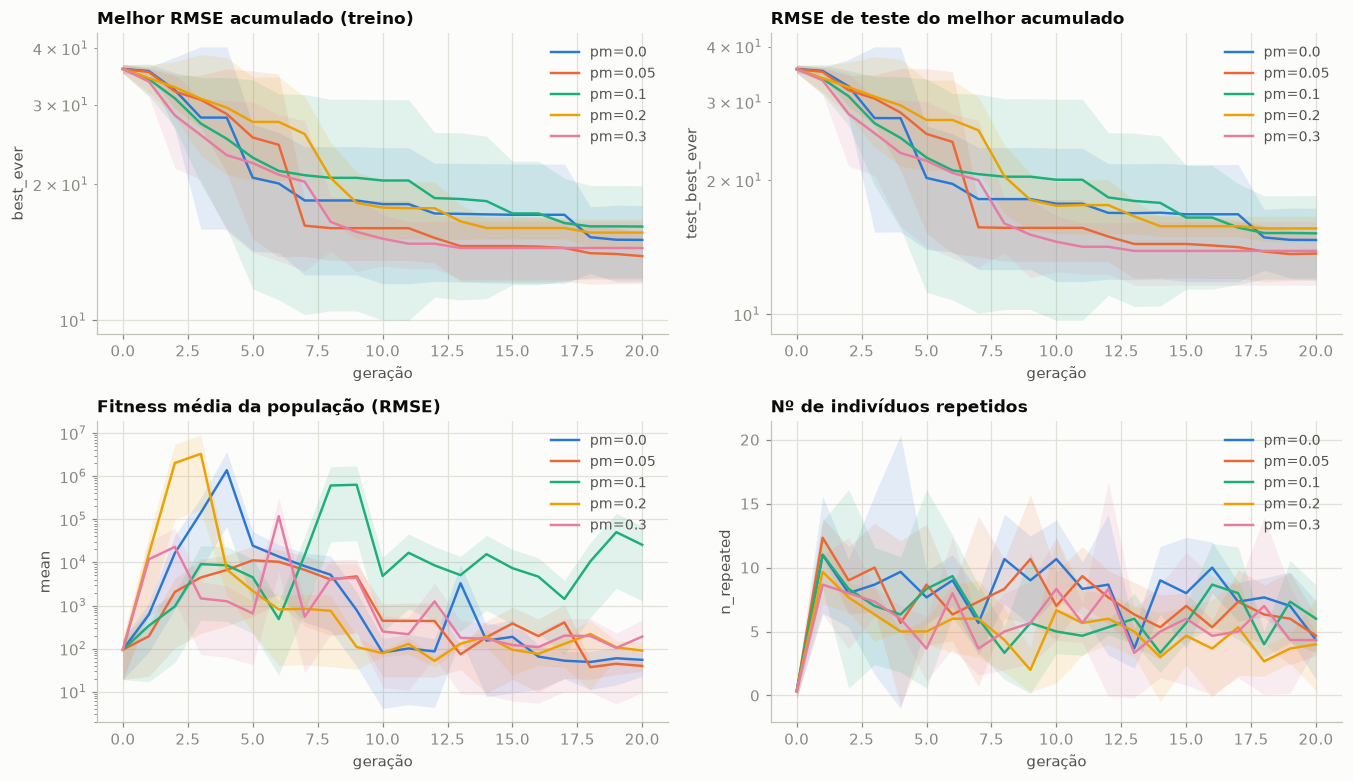

Efeito da mutação:


,mut_indivs,mut_melhor_%,mut_igual_%,mut_pior_%
pm=0.0,0.0,NaN,NaN,NaN
pm=0.05,152.0,37.50,0.00,62.50
pm=0.1,304.0,35.53,1.32,63.16
pm=0.2,604.0,39.90,0.99,59.11
pm=0.3,878.0,31.09,1.14,67.77


In [15]:
# ✍️ Decisão sobre pc (padrão: menor RMSE médio de treino). Sobrescreva com PC_OVERRIDE = {"synth1": 0.9}
PC_OVERRIDE = {}
for n in STUDY:
    pc = PC_OVERRIDE.get(n) or float(best_config(pc_res[n]).split("=")[1])
    CHOSEN[n] = CHOSEN[n].replace(pc=pc)
    print(f"{n}: pc = {pc}")

for n in STUDY:
    pm_res[n] = sweep(CHOSEN[n], "pm", PM_VALUES, DATA[n], n_runs=N_RUNS, base_seed=BASE_SEED, n_jobs=N_JOBS)
    report(pm_res[n], title=f"{n} — variação de pm (pc = {CHOSEN[n].pc})")
    print("Efeito da mutação:")
    display(operator_effects(pm_res[n])[["mut_indivs", "mut_melhor_%", "mut_igual_%", "mut_pior_%"]].round(2))

## Análise (3.3)

> **Resultado:** a mutação intermediária foi a mais útil na `synth1`: `p_m=0,05` teve RMSE 2,77/4,74, enquanto `p_m=0` teve 5,72/8,11 e taxas maiores (`0,1`–`0,3`) pioraram o teste para 8,80–10,89. Na `concrete`, a configuração escolhida também foi `p_m=0,05` por consistência com a comparação inicial; o melhor valor isolado não é robusto com três execuções. Nenhuma diferença foi significativa após Holm (p ajustado mínimo 1,0 na comparação de `pm`). Portanto, a mutação ajuda a escapar da estagnação quando moderada, mas excesso de mutações destrói boas subárvores.

In [ ]:
# Decisão sobre pm (padrão: menor RMSE médio de treino). Podem sobrescrevar com, ex: PM_OVERRIDE = {"synth1": 0.1}
PM_OVERRIDE = {}
for n in STUDY:
    pm = PM_OVERRIDE.get(n) or float(best_config(pm_res[n]).split("=")[1])
    CHOSEN[n] = CHOSEN[n].replace(pm=pm)
    print(f"{n}: pm = {pm}")

### 3.3.3 Os parâmetros anteriores ainda são apropriados?

Com $p_c$ e $p_m$ ajustados, repetimos a comparação de método de seleção e de tamanho da população
para verificar se as conclusões anteriores se mantêm (o guia pergunta isso explicitamente). Set `RECHECK = False` se o tempo for curto.

synth1: 3 config × 3 runs:   0%|          | 0/9 [00:00<?, ?it/s]

[synth1] 9 execuções em 0.3s


#### synth1 — seleção, com pc=0.9 e pm=0.05

,train_mean,train_std,train_median,test_mean,test_std,test_median,gap_mean,best_size,best_depth,time_s,n_runs
roulette,7.1784,4.3368,9.0279,10.6683,6.7623,12.0020,3.4899,9.3333,4.3333,0.0307,3.0
tournament k=2,8.5159,1.3695,8.9032,22.1614,16.1120,16.6078,13.6455,19.6667,6.0000,0.0405,3.0
lexicase (ε-MAD),2.7660,0.5755,2.9513,4.7430,1.8713,5.2738,1.9770,17.6667,6.3333,0.1744,3.0


Kruskal-Wallis (train_rmse): p = 0.1931


,a,b,mediana_a,mediana_b,p,p_holm,signif_5%
0,roulette,tournament k=2,9.0279,8.9032,1.0,1.0,False
1,roulette,lexicase (ε-MAD),9.0279,2.9513,0.4,0.8,False
2,tournament k=2,lexicase (ε-MAD),8.9032,2.9513,0.1,0.3,False


Kruskal-Wallis (test_rmse): p = 0.1479


,a,b,mediana_a,mediana_b,p,p_holm,signif_5%
0,roulette,tournament k=2,12.0020,16.6078,0.7,0.8,False
1,roulette,lexicase (ε-MAD),12.0020,5.2738,0.4,0.8,False
2,tournament k=2,lexicase (ε-MAD),16.6078,5.2738,0.1,0.3,False


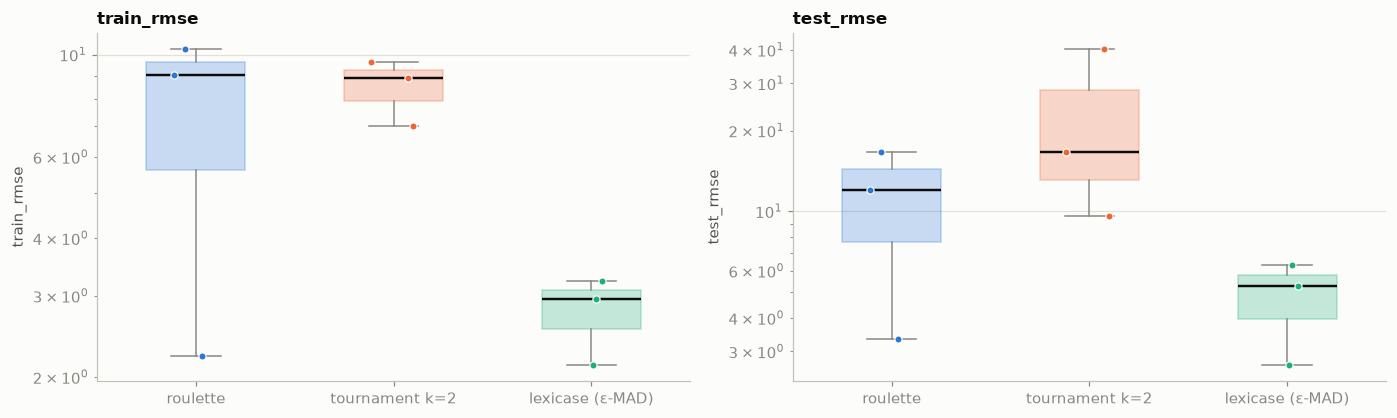

synth1: 2 config × 3 runs:   0%|          | 0/6 [00:00<?, ?it/s]

[synth1] 6 execuções em 0.2s


#### synth1 — população, com pc=0.9 e pm=0.05

,train_mean,train_std,train_median,test_mean,test_std,test_median,gap_mean,best_size,best_depth,time_s,n_runs
pop_size=20,8.5964,5.1002,9.9656,15.3821,7.8743,19.7569,6.7857,22.3333,6.0000,0.0608,3.0
pop_size=50,2.7660,0.5755,2.9513,4.7430,1.8713,5.2738,1.9770,17.6667,6.3333,0.1733,3.0


Kruskal-Wallis (train_rmse): p = 0.184


,a,b,mediana_a,mediana_b,p,p_holm,signif_5%
0,pop_size=20,pop_size=50,9.9656,2.9513,0.2683,0.2683,False


Kruskal-Wallis (test_rmse): p = 0.07652


,a,b,mediana_a,mediana_b,p,p_holm,signif_5%
0,pop_size=20,pop_size=50,19.7569,5.2738,0.1212,0.1212,False


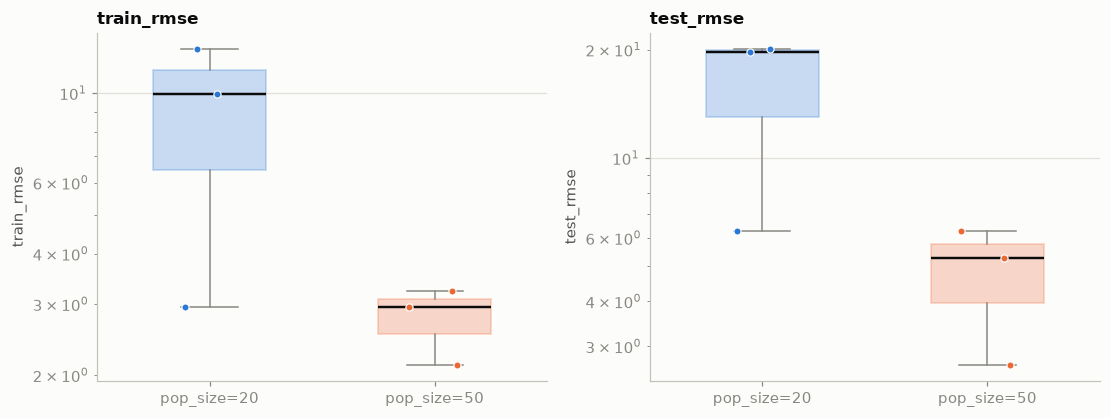

concrete: 3 config × 3 runs:   0%|          | 0/9 [00:00<?, ?it/s]

[concrete] 9 execuções em 2.1s


#### concrete — seleção, com pc=0.7 e pm=0.05

,train_mean,train_std,train_median,test_mean,test_std,test_median,gap_mean,best_size,best_depth,time_s,n_runs
roulette,20.8382,5.5651,19.3834,19.8425,4.7307,19.1111,-0.9957,12.3333,5.3333,0.0358,3.0
tournament k=2,16.4686,1.6185,17.1087,16.0215,1.8106,16.6684,-0.4470,30.3333,7.0000,0.0329,3.0
lexicase (ε-MAD),13.8677,1.8031,14.4085,13.6953,1.7201,14.6467,-0.1724,29.3333,7.0000,1.7752,3.0


Kruskal-Wallis (train_rmse): p = 0.07939


,a,b,mediana_a,mediana_b,p,p_holm,signif_5%
0,roulette,tournament k=2,19.3834,17.1087,0.4,0.4,False
1,roulette,lexicase (ε-MAD),19.3834,14.4085,0.1,0.3,False
2,tournament k=2,lexicase (ε-MAD),17.1087,14.4085,0.2,0.4,False


Kruskal-Wallis (test_rmse): p = 0.1133


,a,b,mediana_a,mediana_b,p,p_holm,signif_5%
0,roulette,tournament k=2,19.1111,16.6684,0.4,0.8,False
1,roulette,lexicase (ε-MAD),19.1111,14.6467,0.1,0.3,False
2,tournament k=2,lexicase (ε-MAD),16.6684,14.6467,0.4,0.8,False


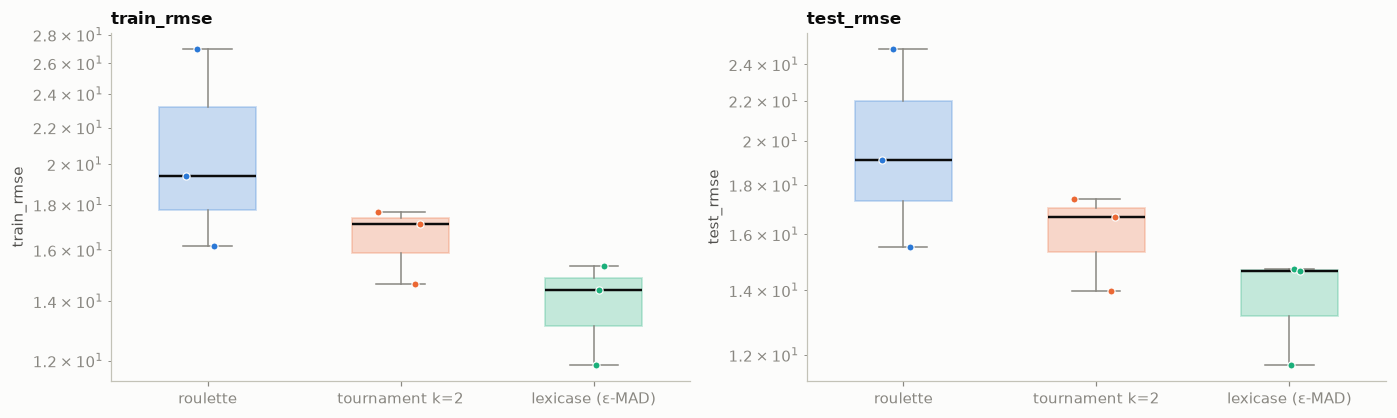

concrete: 2 config × 3 runs:   0%|          | 0/6 [00:00<?, ?it/s]

[concrete] 6 execuções em 2.6s


#### concrete — população, com pc=0.7 e pm=0.05

,train_mean,train_std,train_median,test_mean,test_std,test_median,gap_mean,best_size,best_depth,time_s,n_runs
pop_size=20,24.1976,8.6481,21.7256,23.9141,8.7328,21.2482,-0.2835,32.6667,7.0,1.422,3.0
pop_size=50,13.8677,1.8031,14.4085,13.6953,1.7201,14.6467,-0.1724,29.3333,7.0,2.282,3.0


Kruskal-Wallis (train_rmse): p = 0.04953


,a,b,mediana_a,mediana_b,p,p_holm,signif_5%
0,pop_size=20,pop_size=50,21.7256,14.4085,0.1,0.1,False


Kruskal-Wallis (test_rmse): p = 0.04953


,a,b,mediana_a,mediana_b,p,p_holm,signif_5%
0,pop_size=20,pop_size=50,21.2482,14.6467,0.1,0.1,False


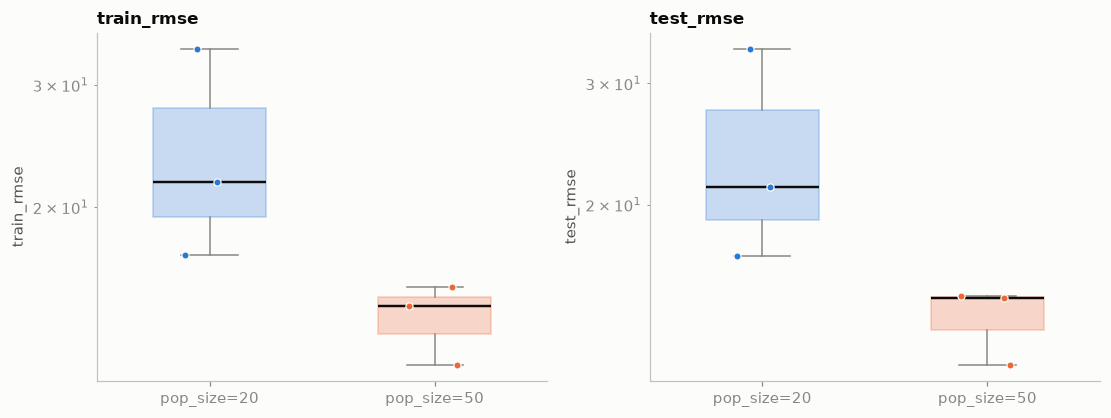

In [17]:
RECHECK = True
if RECHECK:
    for n in STUDY:
        re_sel = compare_configs(selection_configs(CHOSEN[n]), DATA[n], n_runs=N_RUNS,
                                 base_seed=BASE_SEED, n_jobs=N_JOBS)
        report(re_sel, title=f"{n} — seleção, com pc={CHOSEN[n].pc} e pm={CHOSEN[n].pm}", curves=())
        re_pop = sweep(CHOSEN[n], "pop_size", POP_SIZES, DATA[n], n_runs=N_RUNS,
                       base_seed=BASE_SEED, n_jobs=N_JOBS)
        report(re_pop, title=f"{n} — população, com pc={CHOSEN[n].pc} e pm={CHOSEN[n].pm}", curves=())

## Análise (3.3.3)
>
> **Resultado:** com os parâmetros ajustados, a preferência pelo ε-lexicase e por população 50 permaneceu. Na `synth1`, a população 50 passou de 8,60 para 2,77 de RMSE médio de treino em relação à população 20; na `concrete`, passou de 24,20 para 13,87. As comparações de seleção também continuaram favorecendo o lexicase. As diferenças não foram significativas após Holm (p ajustado mínimo 0,10), mas a direção dos resultados foi consistente; não houve motivo para alterar `CHOSEN`.

## 3.4 Passo 4 — Elitismo

Com os melhores parâmetros até aqui, comparamos **sem elitismo** (`n_elite=0`), com **1 elitista** e com
**5 elitistas**. Sem elitismo o melhor indivíduo da população pode piorar de uma geração para outra —
por isso, além do melhor acumulado, vale olhar a curva do **melhor da geração** (`best`).

synth1: 3 config × 3 runs:   0%|          | 0/9 [00:00<?, ?it/s]

[synth1] 9 execuções em 0.3s


#### synth1 — elitismo

,train_mean,train_std,train_median,test_mean,test_std,test_median,gap_mean,best_size,best_depth,time_s,n_runs
n_elite=0,8.1094,1.4202,8.6332,9.2829,2.6762,9.3503,1.1735,22.0000,5.6667,0.1257,3.0
n_elite=1,2.7660,0.5755,2.9513,4.7430,1.8713,5.2738,1.9770,17.6667,6.3333,0.1794,3.0
n_elite=5,5.3167,2.6330,6.4468,7.7231,4.4600,9.4203,2.4064,20.6667,6.3333,0.1916,3.0


Kruskal-Wallis (train_rmse): p = 0.07939


,a,b,mediana_a,mediana_b,p,p_holm,signif_5%
0,n_elite=0,n_elite=1,8.6332,2.9513,0.1,0.3,False
1,n_elite=0,n_elite=5,8.6332,6.4468,0.2,0.4,False
2,n_elite=1,n_elite=5,2.9513,6.4468,0.4,0.4,False


Kruskal-Wallis (test_rmse): p = 0.2107


,a,b,mediana_a,mediana_b,p,p_holm,signif_5%
0,n_elite=0,n_elite=1,9.3503,5.2738,0.1000,0.3,False
1,n_elite=0,n_elite=5,9.3503,9.4203,1.0000,1.0,False
2,n_elite=1,n_elite=5,5.2738,9.4203,0.5066,1.0,False


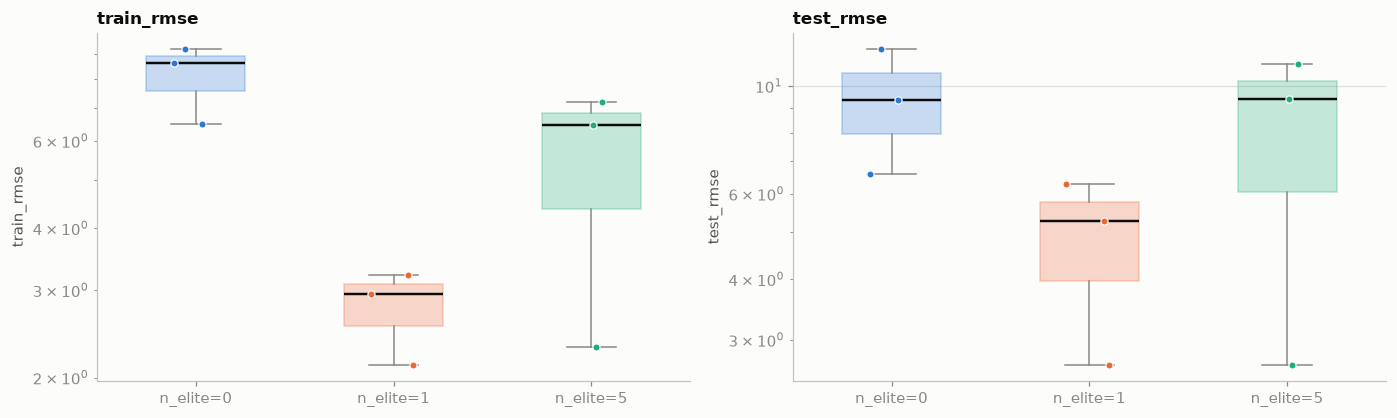

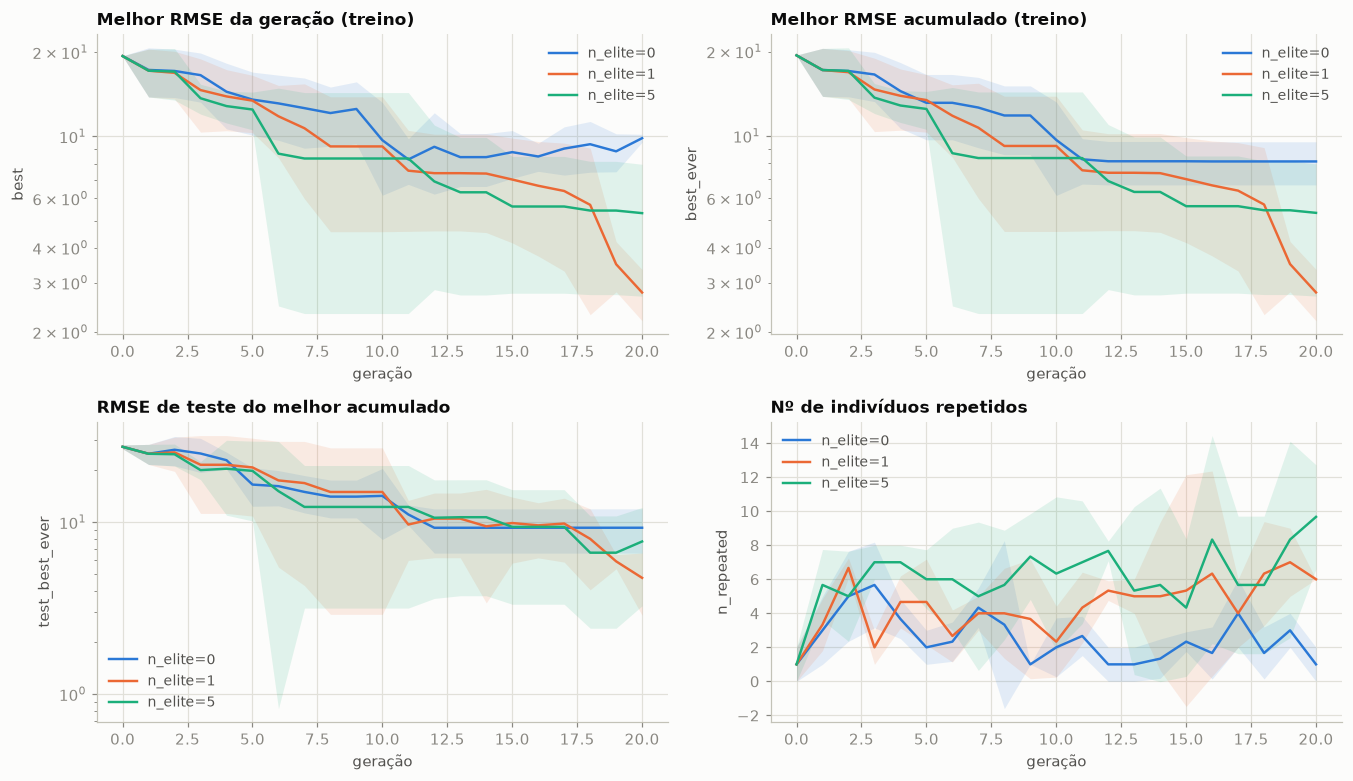

concrete: 3 config × 3 runs:   0%|          | 0/9 [00:00<?, ?it/s]

[concrete] 9 execuções em 2.8s


#### concrete — elitismo

,train_mean,train_std,train_median,test_mean,test_std,test_median,gap_mean,best_size,best_depth,time_s,n_runs
n_elite=0,15.0347,2.4336,15.4786,14.7997,2.4137,15.5287,-0.2350,29.3333,7.0,1.6400,3.0
n_elite=1,13.8677,1.8031,14.4085,13.6953,1.7201,14.6467,-0.1724,29.3333,7.0,1.8678,3.0
n_elite=5,15.4597,1.0151,15.0164,14.8764,1.0496,14.4665,-0.5833,25.3333,7.0,1.6957,3.0


Kruskal-Wallis (train_rmse): p = 0.4298


,a,b,mediana_a,mediana_b,p,p_holm,signif_5%
0,n_elite=0,n_elite=1,15.4786,14.4085,0.4,1.0,False
1,n_elite=0,n_elite=5,15.4786,15.0164,1.0,1.0,False
2,n_elite=1,n_elite=5,14.4085,15.0164,0.4,1.0,False


Kruskal-Wallis (test_rmse): p = 0.6703


,a,b,mediana_a,mediana_b,p,p_holm,signif_5%
0,n_elite=0,n_elite=1,15.5287,14.6467,0.4,1.0,False
1,n_elite=0,n_elite=5,15.5287,14.4665,1.0,1.0,False
2,n_elite=1,n_elite=5,14.6467,14.4665,1.0,1.0,False


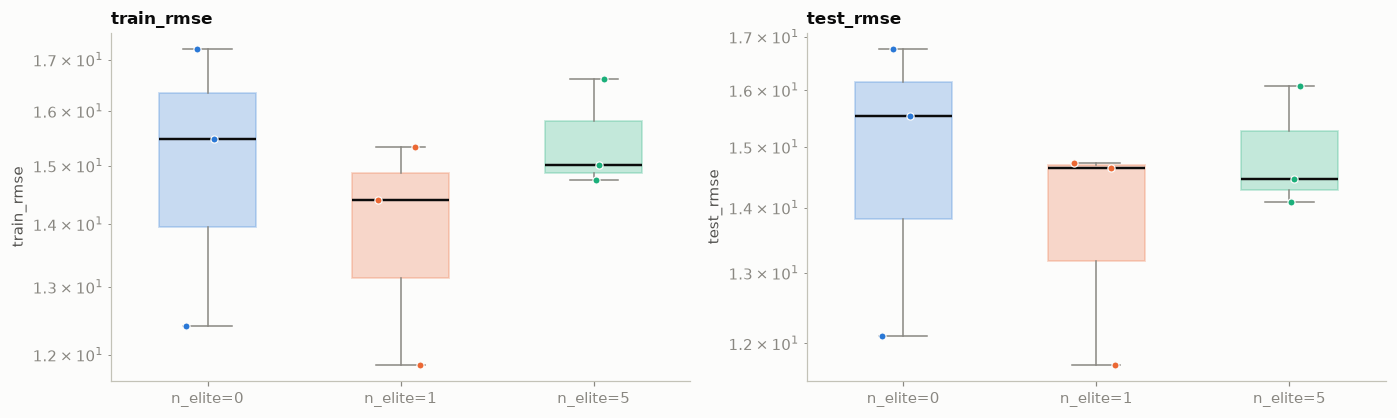

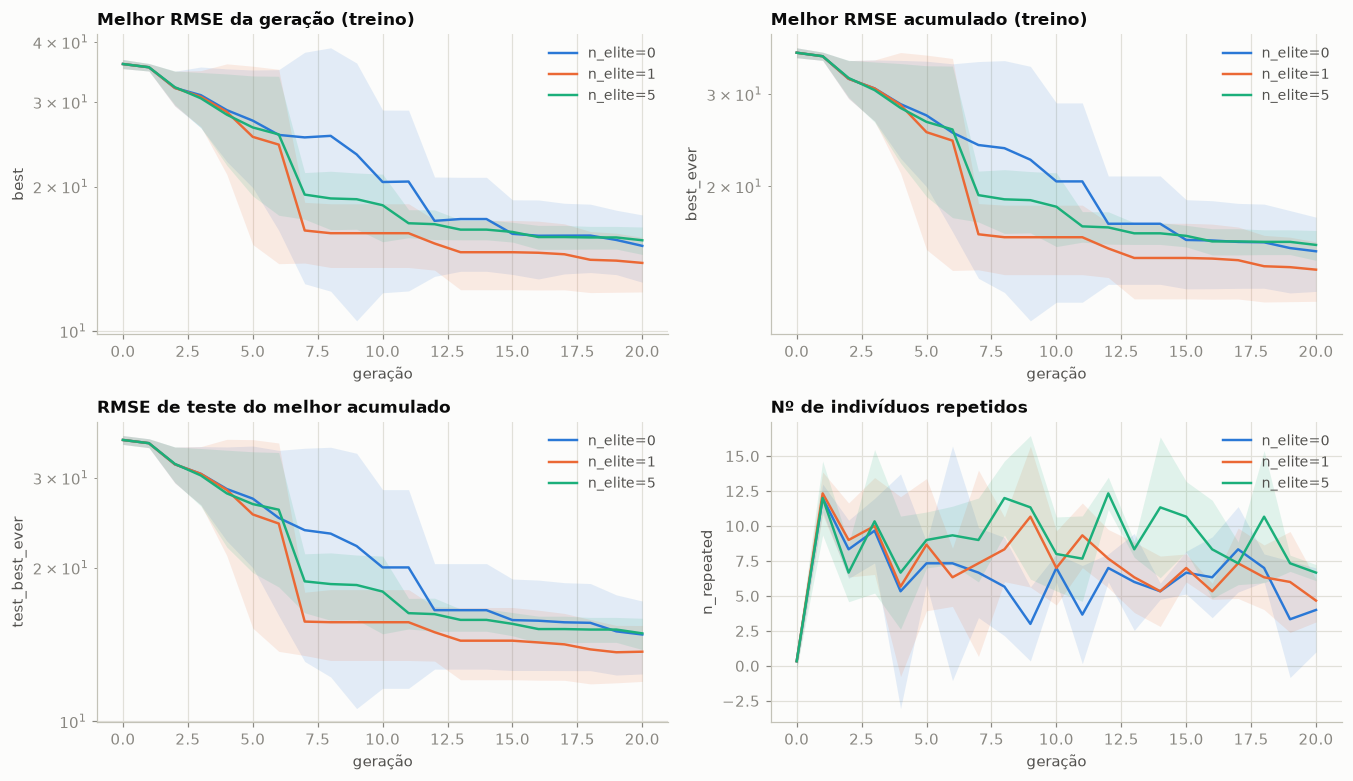

In [18]:
elit_res = {}
for n in STUDY:
    elit_res[n] = sweep(CHOSEN[n], "n_elite", [0, 1, 5], DATA[n], n_runs=N_RUNS,
                        base_seed=BASE_SEED, n_jobs=N_JOBS)
    report(elit_res[n], title=f"{n} — elitismo",
           curves=(("best", "Melhor RMSE da geração (treino)", True),
                   ("best_ever", "Melhor RMSE acumulado (treino)", True),
                   ("test_best_ever", "RMSE de teste do melhor acumulado", True),
                   ("n_repeated", "Nº de indivíduos repetidos", False)))

## Análise (3.4)
>
> **Resultado:** um elitista foi a melhor opção média nas duas bases. Na `synth1`, `n_elite=1` teve treino/teste 2,77/4,74, contra 8,11/9,28 sem elitismo e 5,32/7,72 com cinco elitistas. Na `concrete`, `n_elite=1` também foi melhor (13,87/13,70). Sem elitismo, o melhor da geração pode oscilar e o bloat foi maior na `synth1`; cinco elitistas reduziu a exploração e não melhorou o erro. Os testes não foram significativos após Holm, então a conclusão é de desempenho observado, não de diferença comprovada.

In [19]:
# ✍️ Decisão sobre elitismo (padrão: menor RMSE médio de treino). Sobrescreva com ELITE_OVERRIDE = {"synth1": 1}
ELITE_OVERRIDE = {}
for n in STUDY:
    ne = ELITE_OVERRIDE.get(n)
    if ne is None:
        ne = int(best_config(elit_res[n]).split("=")[1])
    CHOSEN[n] = CHOSEN[n].replace(n_elite=ne)
    print(f"{n}: n_elite = {ne}")

synth1: n_elite = 1
concrete: n_elite = 1


## 3.5 *Bloat*: existe uma forma simples de medi-lo?

*Bloat* é o crescimento do tamanho dos indivíduos **sem melhora correspondente de fitness**. Como cada
geração já registra o tamanho e a profundidade médios da população e o fitness do melhor indivíduo,
medimos o bloat de duas formas simples:

1. **Curva do tamanho médio** (nº de nós) e da profundidade média por geração — se cresce de forma
   contínua enquanto o erro estagna, há bloat;
2. **Razão** $\dfrac{\text{tamanho médio final}/\text{tamanho médio inicial}}{\text{RMSE inicial}/\text{RMSE final}}$
   (`size_vs_fitness` em `bloat_table`): quanto o tamanho cresceu relativamente ao ganho de qualidade.
   Valores muito maiores que 1 indicam bloat.

Neste trabalho o crescimento é naturalmente **limitado** pela profundidade máxima 7 (controle por limite
de profundidade, como em Koza), então é esperado que o tamanho médio sature; o que interessa ver é com que
rapidez isso ocorre e como varia com o método de seleção e com o elitismo.


================  synth1  ================
Medidas de bloat — seleção:


,size_growth,final_avg_size,final_avg_depth,final_best_size,fitness_gain,size_vs_fitness
roulette,0.998,7.833,3.867,9.333,4.245,0.235
tournament k=2,2.319,18.207,5.673,19.667,2.318,1.001
lexicase (ε-MAD),2.279,17.927,5.873,17.667,7.235,0.315


Medidas de bloat — elitismo:


,size_growth,final_avg_size,final_avg_depth,final_best_size,fitness_gain,size_vs_fitness
n_elite=0,3.143,24.693,6.367,22.000,2.444,1.286
n_elite=1,2.279,17.927,5.873,17.667,7.235,0.315
n_elite=5,2.517,19.793,6.080,20.667,4.696,0.536


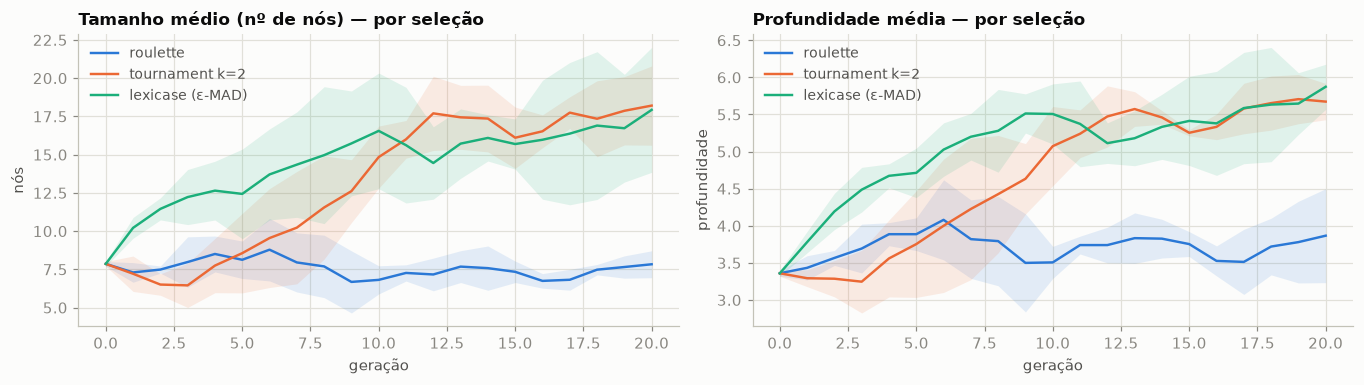


================  concrete  ================
Medidas de bloat — seleção:


,size_growth,final_avg_size,final_avg_depth,final_best_size,fitness_gain,size_vs_fitness
roulette,1.491,11.713,5.093,12.667,2.087,0.714
tournament k=2,2.742,21.620,6.733,24.000,2.263,1.212
lexicase (ε-MAD),4.659,36.760,6.960,35.000,2.451,1.901


Medidas de bloat — elitismo:


,size_growth,final_avg_size,final_avg_depth,final_best_size,fitness_gain,size_vs_fitness
n_elite=0,3.934,31.000,6.847,29.333,2.434,1.617
n_elite=1,4.048,31.867,6.733,29.333,2.623,1.543
n_elite=5,3.394,26.727,6.673,25.333,2.333,1.455


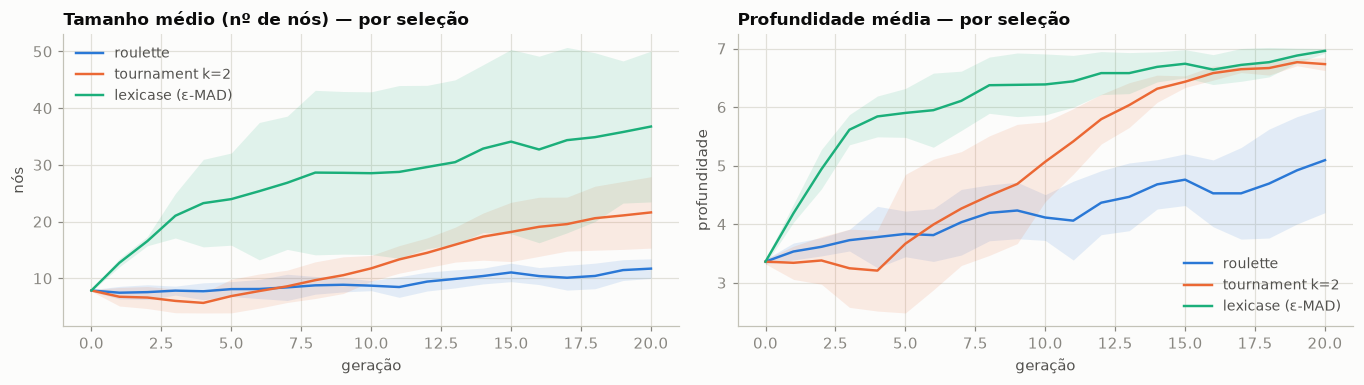

In [20]:
for n in STUDY:
    print(f"\n================  {n}  ================")
    for titulo, res in [("seleção", sel_res[n]), ("elitismo", elit_res[n])]:
        print(f"Medidas de bloat — {titulo}:")
        display(bloat_table(res).round(3))
    fig, axes = plt.subplots(1, 2, figsize=(12.5, 3.6))
    P.plot_curves(sel_res[n], "avg_size", ax=axes[0], title="Tamanho médio (nº de nós) — por seleção", ylabel="nós")
    P.plot_curves(sel_res[n], "avg_depth", ax=axes[1], title="Profundidade média — por seleção", ylabel="profundidade")
    fig.tight_layout(); plt.show()

## Análise (3.5)
>
> **Resultado:** há bloat, mas ele depende da base e do operador. Na `synth1`, o tamanho médio final cresceu 2,28 vezes com lexicase e a profundidade média chegou a 5,87; a razão `size_vs_fitness` foi 0,315, menor que a do torneio (1,001). Na `concrete`, o lexicase apresentou o maior crescimento (4,659 vezes) e `size_vs_fitness=1,901`, indicando que o aumento estrutural superou o ganho de fitness. Com elitismo, a `concrete` também mostrou crescimento elevado (3,394–4,048 vezes), embora cinco elitistas tenha reduzido a razão para 1,455.
>
> O limite de profundidade 7 explica a saturação das curvas de profundidade. Os melhores indivíduos não são necessariamente menores que a média: na `synth1` o melhor do lexicase tem tamanho médio 17,67 contra 17,93 da população, mas na `concrete` tem 35 contra 36,76; são apenas ligeiramente menores. O limite evita crescimento ilimitado, porém não elimina bloat.

## 3.6 (Opcional) Outras características: Diversidade

A coluna `n_repeated` já permite observar a perda de diversidade (indivíduos repetidos) em todas as comparações acima; extensões
possíveis (mas ainda não implementadas, por opção) incluem penalizar as duplicatas, pressão de parcimônia contra o
bloat e mutação de constantes com otimização local.

## 3.7 Configuração final

Reavaliamos a configuração escolhida com seeds novas (`BASE_SEED + 1000`), independentes das usadas
na calibração, e reportamos treino Vs teste. Como referência de escala, comparamos com o RMSE de um modelo
trivial que sempre prevê a média de y do treino.


================  synth1  ================
Configuração final: {'pop_size': 50, 'generations': 20, 'max_depth': 7, 'pc': 0.9, 'pm': 0.05, 'selection': 'lexicase', 'tournament_size': 2, 'lexicase_epsilon': 'dynamic', 'n_elite': 1, 'mutation': 'subtree'}


synth1: 1 config × 3 runs:   0%|          | 0/3 [00:00<?, ?it/s]

[synth1] 3 execuções em 0.2s
RMSE de teste do modelo trivial (prever a média do treino): 26.35


,train_mean,train_std,train_median,test_mean,test_std,test_median,gap_mean,best_size,best_depth,time_s,n_runs
final,7.6178,1.1439,7.2402,10.6689,1.5629,10.5711,3.0511,24.6667,7.0,0.1432,3.0


Melhores execuções (por RMSE de treino):


,seed,train_rmse,test_rmse,size,depth,expression
1,1001,6.710398,10.571082,24,7,(((x0 * x0) - (4.043 * x0)) + (cos((4.043 * x0)) - ((((x0 * 2.887) * -1.695) * x0) / (x1 / x1))))
0,1000,7.240199,9.157218,34,7,(((((x0 * -1.955) * (x0 * -3.858)) + (x0 * -1.955)) + (x0 * -1.955)) + ((x0 * -1.955) + (((x1 - x0) * cos(2.981)) * ...
2,1002,8.902705,12.278356,16,7,((x0 + ((x0 + x0) - cos((x0 * (x0 - x1))))) * (x0 + x0))


Melhor expressão encontrada:
   (((x0 * x0) - (4.043 * x0)) + (cos((4.043 * x0)) - ((((x0 * 2.887) * -1.695) * x0) / (x1 / x1))))


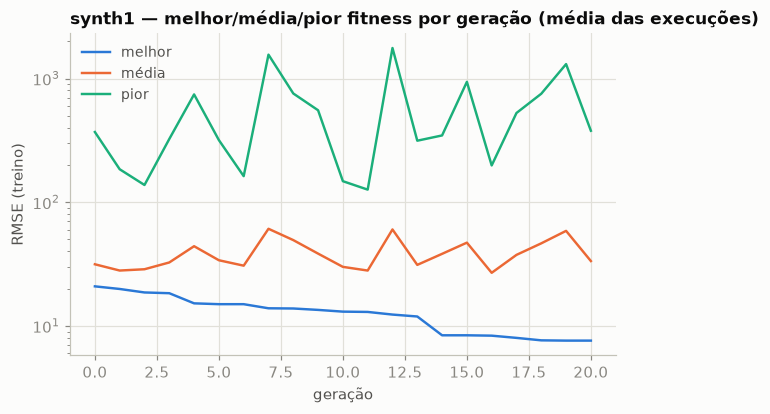

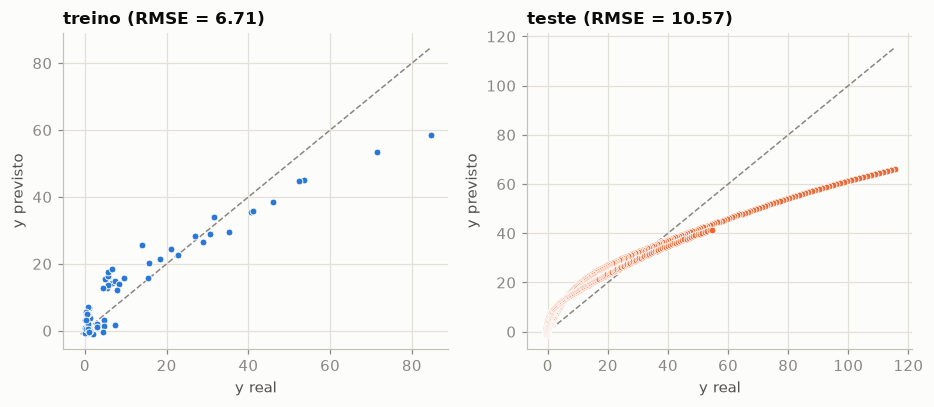

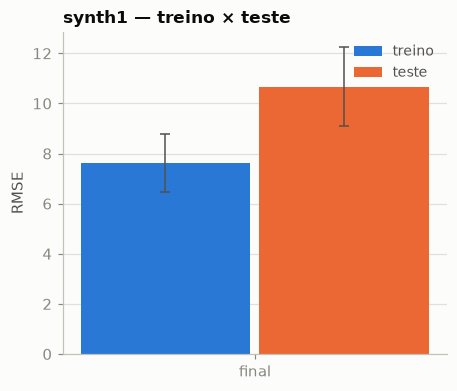


================  concrete  ================
Configuração final: {'pop_size': 50, 'generations': 20, 'max_depth': 7, 'pc': 0.7, 'pm': 0.05, 'selection': 'lexicase', 'tournament_size': 2, 'lexicase_epsilon': 'dynamic', 'n_elite': 1, 'mutation': 'subtree'}


concrete: 1 config × 3 runs:   0%|          | 0/3 [00:00<?, ?it/s]

[concrete] 3 execuções em 1.4s
RMSE de teste do modelo trivial (prever a média do treino): 16.27


,train_mean,train_std,train_median,test_mean,test_std,test_median,gap_mean,best_size,best_depth,time_s,n_runs
final,25.4409,10.9761,22.667,25.163,10.9073,22.6292,-0.2779,13.0,4.6667,1.1506,3.0


Melhores execuções (por RMSE de treino):


,seed,train_rmse,test_rmse,size,depth,expression
0,1000,16.117866,15.745574,17,5,((((x3 * -3.858) / (x0 / x0)) + (2.645 + 4.769)) - ((2.645 + 4.769) * -3.966))
2,1002,22.667046,22.629221,17,6,((x1 * (x5 + (x5 + (-4.741 / x1)))) * (x1 * (x5 + (-4.741 / x1))))
1,1001,37.537917,37.114235,5,3,((-0.6689 + 3.018) - x1)


Melhor expressão encontrada:
   ((((x3 * -3.858) / (x0 / x0)) + (2.645 + 4.769)) - ((2.645 + 4.769) * -3.966))


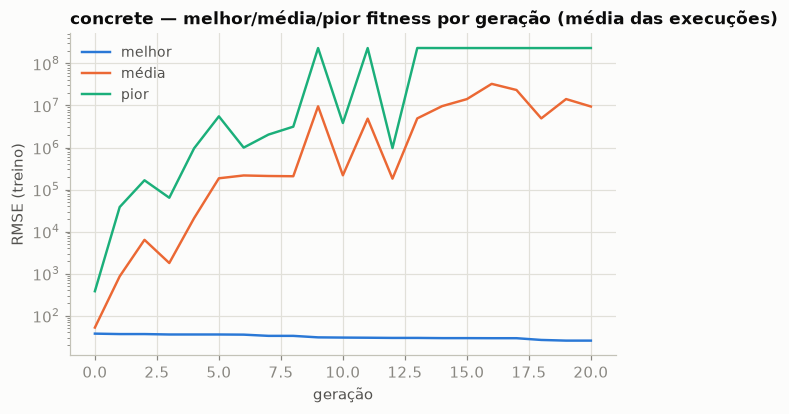

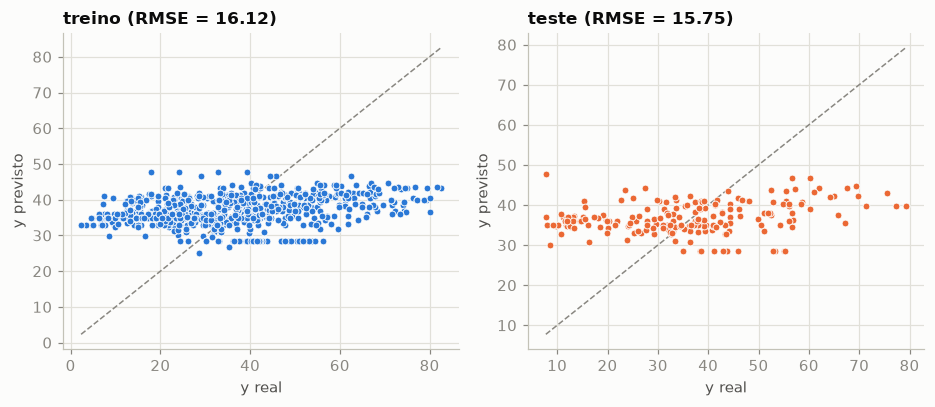

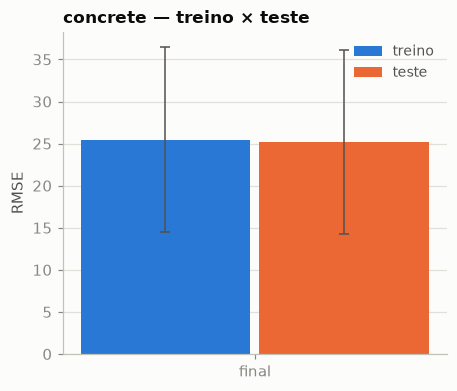

In [21]:
final_res = {}
for n in STUDY:
    cfg = CHOSEN[n]
    print(f"\n================  {n}  ================")
    print("Configuração final:", {k: v for k, v in cfg.to_dict().items()
                                   if k in ("pop_size", "generations", "max_depth", "selection", "tournament_size",
                                            "lexicase_epsilon", "pc", "pm", "n_elite", "mutation")})
    final_res[n] = compare_configs({"final": cfg}, DATA[n], n_runs=N_RUNS,
                                   base_seed=BASE_SEED + 1000, n_jobs=N_JOBS)
    rep = final_res[n]["final"]

    d = DATA[n]
    base_rmse = float(np.sqrt(np.mean((d.y_test - d.y_train.mean()) ** 2)))
    print(f"RMSE de teste do modelo trivial (prever a média do treino): {base_rmse:.4g}")
    display(summary_table(final_res[n]).round(4))

    print("Melhores execuções (por RMSE de treino):")
    display(rep.final.sort_values("train_rmse").head(5)[["seed", "train_rmse", "test_rmse", "size", "depth", "expression"]])
    print("Melhor expressão encontrada:\n  ", rep.best_run.expression)

    P.plot_population_stats(rep, title=f"{n} — melhor/média/pior fitness por geração (média das execuções)")
    plt.show()
    P.plot_prediction(rep.best_run, d); plt.show()
    P.plot_train_test(final_res[n], title=f"{n} — treino × teste"); plt.show()

## Análise (3.7)
>
> **Resultado:** na avaliação final com sementes novas, a configuração escolhida para a `synth1` obteve RMSE 7,62 ± 1,14 no treino e 10,67 ± 1,56 no teste, contra 26,35 do preditor trivial no teste. O gap positivo (3,05) indica algum sobreajuste, mas a expressão encontrada é relativamente compacta (24 nós) e combina operações sobre `x0` e `x1`. Na `concrete`, o resultado foi 25,44 ± 10,98 no treino e 25,16 ± 10,91 no teste, pior que o trivial (16,27); a alta variância mostra instabilidade e a expressão vencedora não generaliza de forma confiável. Seriam necessárias mais repetições, melhor calibração e controle de bloat para uma conclusão definitiva.

## 3.8 Generalização dos parâmetros para a outra base sintética

Os parâmetros escolhidos para `synth1` são reaplicados, **sem nova calibração**, à base `synth2`
(se disponível em `data/`).

synth2: 1 config × 3 runs:   0%|          | 0/3 [00:00<?, ?it/s]

[synth2] 3 execuções em 0.5s
RMSE de teste do modelo trivial (média do treino): 4.036


,train_mean,train_std,train_median,test_mean,test_std,test_median,gap_mean,best_size,best_depth,time_s,n_runs
synth2 (params de synth1),2.6664,0.7532,2.8049,3.0896,1.0737,3.6074,0.4232,22.6667,6.3333,0.4207,3.0


Melhor expressão encontrada:
   ((((((-4.516 + 1.362) / (-4.079 + 1.568)) + (x1 / x1)) - x1) - cos(2.537)) * ((sin(-0.6117) - (((x0 + x1) * (x0 / x0)) - x1)) - -4.228))


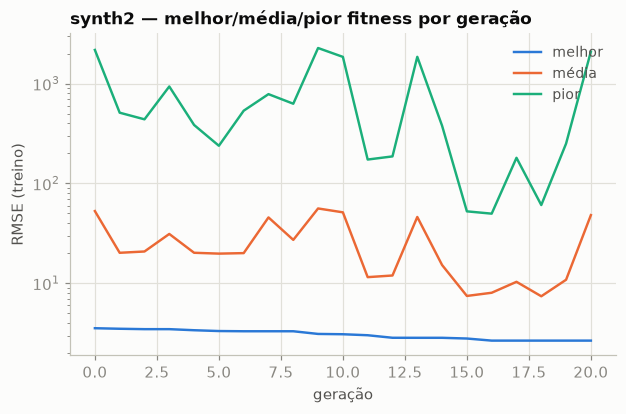

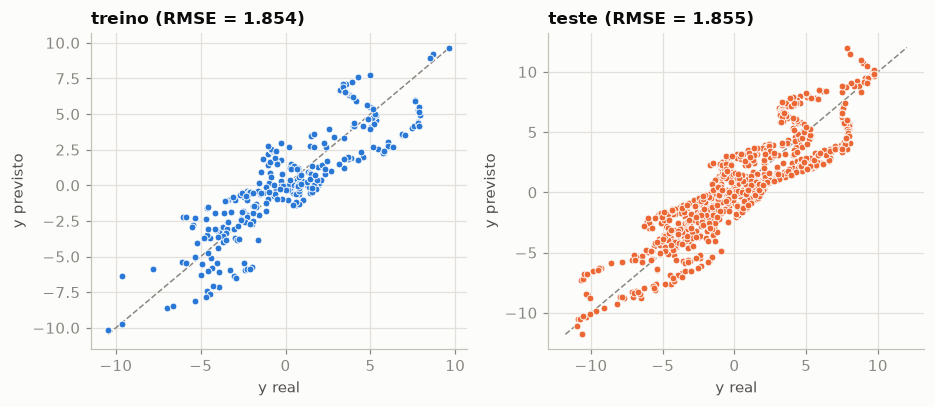

In [22]:
if SYNTH_OTHER in DATA and SYNTH_STUDY in CHOSEN:
    cfg2 = CHOSEN[SYNTH_STUDY]
    res2 = compare_configs({f"{SYNTH_OTHER} (params de {SYNTH_STUDY})": cfg2}, DATA[SYNTH_OTHER],
                           n_runs=N_RUNS, base_seed=BASE_SEED + 1000, n_jobs=N_JOBS)
    rep2 = next(iter(res2.values()))
    d2 = DATA[SYNTH_OTHER]
    print(f"RMSE de teste do modelo trivial (média do treino): {np.sqrt(np.mean((d2.y_test - d2.y_train.mean())**2)):.4g}")
    display(summary_table(res2).round(4))
    print("Melhor expressão encontrada:\n  ", rep2.best_run.expression)
    P.plot_population_stats(rep2, title=f"{SYNTH_OTHER} — melhor/média/pior fitness por geração"); plt.show()
    P.plot_prediction(rep2.best_run, d2); plt.show()
else:
    print(f"Base {SYNTH_OTHER!r} não encontrada em data/ — coloque {SYNTH_OTHER}-train.csv e {SYNTH_OTHER}-test.csv e execute de novo.")

## Análise (3.8)

> **Resultado:** os parâmetros escolhidos na `synth1` generalizaram razoavelmente para a `synth2`: RMSE 2,67 ± 0,75 no treino e 3,09 ± 1,07 no teste, ambos próximos, contra 4,04 do modelo trivial no teste. O desempenho relativo é melhor que o trivial, embora o gap de 0,42 e o desvio elevado indiquem algum sobreajuste e variabilidade. Portanto, a transferência foi útil, mas não substitui uma calibração específica da base.

# 4. Conclusões

> **Resumo:** população 50, ε-lexicase, `p_m=0,05` e um elitista foram as escolhas mais consistentes. O melhor `p_c` observado foi 0,9 na `synth1` e 0,7 na `concrete`. A `synth1` apresentou ganho forte sobre o preditor trivial (RMSE de teste 10,67 contra 26,35), e a `synth2` também melhorou (3,09 contra 4,04). Já a configuração final da `concrete` foi instável e ficou pior que o trivial (25,16 contra 16,27), apesar de a calibração preliminar ter favorecido o lexicase.
>
> Houve sinais de sobreajuste na `synth1` e bloat mais expressivo na `concrete`, sobretudo com lexicase. O limite de profundidade 7 conteve o crescimento ilimitado, mas não impediu árvores grandes nem perda de diversidade. 

As conclusões são exploratórias, a execução usa três repetições e 20 gerações, logo os testes de Holm não encontraram diferenças significativas. Para trabalhos trabalhos futuros, poderia ser interessante repetir com 30 sementes, ampliar o número de gerações, usar validação separada, aplicar pressão de parcimônia/penalização de tamanho e calibrar os parâmetros da `concrete` com mais especificamente.

# 5. Bibliografia

1. J. R. Koza. *Genetic Programming: On the Programming of Computers by Means of Natural Selection*. MIT Press, 1992.
2. R. Poli, W. B. Langdon, N. F. McPhee. *A Field Guide to Genetic Programming*. 2008. (Disponível em http://www.gp-field-guide.org.uk)
3. W. La Cava, L. Spector, K. Danai. *Epsilon-lexicase selection for regression*. Proc. GECCO 2016, pp. 741–748.
4. La Cava et al. *ε-Lexicase selection for Regression* (referência indicada no enunciado). https://arxiv.org/pdf/1905.13266.pdf
5. T. Helmuth, L. Spector, J. Matheson. *Solving uncompromising problems with lexicase selection*. IEEE Trans. Evolutionary Computation, 19(5):630–643, 2015.
6. I-C. Yeh. *Modeling of strength of high-performance concrete using artificial neural networks*. Cement and Concrete Research, 28(12):1797–1808, 1998. Base disponível em http://archive.ics.uci.edu/ml/datasets/concrete+compressive+strength
7. Enunciado do Trabalho Prático 1 — Computação Natural, DCC/UFMG, Profa. Gisele L. Pappa.